# Граф заключений (этап 0) и этапы 1–3 (по обвинениям)

Вывод - в папку `данные_этапы_по_обвинениям/`


## Этап 0. Сборка графа

### 0.1. Пути и константы

In [1]:
import re, sqlite3, time
from pathlib import Path
import numpy as np, pandas as pd

HERE = Path.cwd()                                    # папка ноутбука: <папка ноутбука>
DB = HERE.parent / "compas.db"                       # копия базы ProPublica в корне jupyter lab (единственный внешний файл)
OUT = HERE / "данные_этапы_по_обвинениям"  
WINDOW_START = pd.Timestamp("2013-01-01")
STUDY_END = pd.Timestamp("2016-04-01")               
PLACEHOLDER = pd.Timestamp("2020-01-01")
assert DB.exists(), f"не найдена база {DB}"
OUT.mkdir(exist_ok=True)
REPORT = {}                                          # отчёт об очистке -> cleaning_report.csv
print("DB: ", DB); print("OUT:", OUT)

DB:  ..\compas.db
OUT: данные_этапы_по_обвинениям


### 0.2. Загрузка базы

In [2]:
import sqlite3
import pandas as pd

DB_PATH = DB                                     # compas.db в корне jupyter lab
conn = sqlite3.connect(DB_PATH)

# список таблиц
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
print("Таблицы:", tables)

# читаем все таблицы в словарь датафреймов
dfs = {t: pd.read_sql(f'SELECT * FROM "{t}"', conn) for t in tables}
conn.close()

for name, df in dfs.items():
    print(f"{name}: {df.shape[0]} строк × {df.shape[1]} столбцов")

people        = dfs["people"]
compas        = dfs["compas"]
charge        = dfs["charge"]
casearrest    = dfs["casearrest"]
jailhistory   = dfs["jailhistory"]
prisonhistory = dfs["prisonhistory"]

Таблицы: ['casearrest', 'prisonhistory', 'jailhistory', 'compas', 'summary', 'charge', 'people']
casearrest: 128183 строк × 8 столбцов
prisonhistory: 4945 строк × 9 столбцов
jailhistory: 22111 строк × 7 столбцов
compas: 37578 строк × 21 столбцов
summary: 0 строк × 26 столбцов
charge: 148086 строк × 15 столбцов
people: 11757 строк × 41 столбцов


### 0.3. Очистка

In [3]:
CUTOFF = pd.Timestamp("2016-04-01")   # конец периода наблюдения (последние даты в данных — 2016-03-30)
to_dt = lambda s: pd.to_datetime(s, errors="coerce")

def apply_filters(df, name, rules):
    """rules: {описание: булева маска строк, которые нужно УДАЛИТЬ}"""
    bad = pd.Series(False, index=df.index)
    print(f"\n=== {name}: {len(df)} строк")
    for desc, mask in rules.items():
        mask = mask.fillna(False)
        print(f"  {desc}: {mask.sum()} (новых: {(mask & ~bad).sum()})")
        bad |= mask
    out = df[~bad].reset_index(drop=True)
    print(f"  -> осталось {len(out)} (удалено {bad.sum()})")
    return out

clean = {}

# --- jailhistory ---
j = dfs["jailhistory"].copy()
_ti, _to = to_dt(j.in_custody), to_dt(j.out_custody)
_bad = _ti > _to
_same = _bad & (_ti.dt.normalize() == _to.dt.normalize())
j.loc[_same, "out_custody"] = (_to[_same] + pd.Timedelta(hours=12)).dt.strftime("%Y-%m-%d %H:%M:%S.%f")
REPORT["А2: выход раньше входа"] = int(_bad.sum()); REPORT["А2: исправлено +12 ч"] = int(_same.sum())
REPORT["А2: удалено"] = int((_bad & ~_same).sum())
clean["jailhistory"] = apply_filters(j, "jailhistory", {
    "in_custody > out_custody": to_dt(j.in_custody) > to_dt(j.out_custody),
})

# --- prisonhistory ---
pr = dfs["prisonhistory"]
clean["prisonhistory"] = pr.reset_index(drop=True)          # без фильтров

# --- people ---
p = dfs["people"]
REPORT["people: людей (фильтр не применяется)"] = len(p)
clean["people"] = p.reset_index(drop=True)

# --- compas ---
cp = dfs["compas"]
clean["compas"] = cp.reset_index(drop=True)                 # без фильтров

# --- charge ---
ch = dfs["charge"]
clean["charge"] = apply_filters(ch, "charge", {
    "полные дубликаты": ch.drop(columns="id").duplicated(),
})
clean["charge"]["filing_date"] = pd.NaT   # везде заглушка 1800-01-01

# --- casearrest ---
ca = dfs["casearrest"]
clean["casearrest"] = apply_filters(ca, "casearrest", {
    "arrest_date в будущем (2017, 2020, 2049)": to_dt(ca.arrest_date) > CUTOFF,
})

# --- оставляем во всех таблицах только людей, оставшихся в people ---
ids = set(clean["people"]["id"])
for t in ["compas", "charge", "casearrest", "jailhistory", "prisonhistory"]:
    before = len(clean[t])
    clean[t] = clean[t][clean[t].person_id.isin(ids)].reset_index(drop=True)
    print(f"{t}: удалено по person_id не из people — {before - len(clean[t])}")

people, compas, charge, casearrest, jailhistory, prisonhistory = (
    clean[t] for t in ["people", "compas", "charge", "casearrest", "jailhistory", "prisonhistory"])


=== jailhistory: 22111 строк
  in_custody > out_custody: 1 (новых: 1)
  -> осталось 22110 (удалено 1)


  j.loc[_same, "out_custody"] = (_to[_same] + pd.Timedelta(hours=12)).dt.strftime("%Y-%m-%d %H:%M:%S.%f")



=== charge: 148086 строк
  полные дубликаты: 13 (новых: 13)
  -> осталось 148073 (удалено 13)

=== casearrest: 128183 строк
  arrest_date в будущем (2017, 2020, 2049): 3 (новых: 3)
  -> осталось 128180 (удалено 3)
compas: удалено по person_id не из people — 0
charge: удалено по person_id не из people — 0
casearrest: удалено по person_id не из people — 0
jailhistory: удалено по person_id не из people — 0
prisonhistory: удалено по person_id не из people — 0


### 0.4. Таблица заключений: jail + prison

In [4]:
# --- объединяем jail и prison (SQL поверх очищенных таблиц) ---

mem = sqlite3.connect(":memory:")
jailhistory.to_sql("jailhistory", mem, index=False)
prisonhistory.to_sql("prisonhistory", mem, index=False)

custody = pd.read_sql("""
SELECT person_id, first, last, dob, in_custody, out_custody, 'prison' AS source
FROM prisonhistory
UNION ALL
SELECT person_id, first, last, dob, in_custody, out_custody, 'jail' AS source
FROM jailhistory
ORDER BY person_id, in_custody;
""", mem)
mem.close()

custody["custody_id"] = range(len(custody))                                  # номер записи о заключении
custody["in_date"] = pd.to_datetime(custody["in_custody"]).dt.normalize()   # только дата, без времени

print(f"Записей о заключении: {len(custody)}")
print(custody["source"].value_counts().to_string())

Записей о заключении: 27055
source
jail      22110
prison     4945


### 0.5. Привязка обвинений к заключениям

Правила 4.1–4.6 заметки «Логика build_graph»: арест в [вход − 1 день; вход], переводы jail ↔ prison,  остальное — Unknown.

In [5]:
# ======== привязка по заметке «Логика build_graph» (18.11.2026) ========
# арест в [день входа - 1; день входа]: все дела таких арестов. К заключению привязываются обвинения дела
#     с датой не позже дня входа; одно обвинение может быть привязано к нескольким заключениям.
#     Дело, по которому у человека уже было заключение в окне (вход с 01.01.2013), - старое дело:
#     номер (rearrest_case_ids), прошлые заключения (rearrest_prev_custody_ids), число новых обвинений по делу
#     после прошлого заключения (rearrest_new_charges_n). Только старое дело -> rearrest_old_case (узел OldCase);
#     есть новое дело -> new_offense (состояние - типы нового дела, старое - пометкой).
#  перевод jail -> prison или prison -> jail (разрыв меньше суток;) 
#     наследует дело первого заключения цепочки и склеивается с ним в один узел.
#  остальные - не привязаны (Unknown).
DAY  = pd.Timedelta("1D")
WINDOW_START = pd.Timestamp("2013-01-01")

custody["in_dt"]   = pd.to_datetime(custody["in_custody"])
custody["out_dt"]  = pd.to_datetime(custody["out_custody"])
custody["in_date"] = custody["in_dt"].dt.normalize()
ch = charge.assign(charge_date=pd.to_datetime(charge["date_charge_filed"]).dt.normalize())
ca = casearrest.assign(arrest_date=pd.to_datetime(casearrest["arrest_date"]).dt.normalize())
ca["first_arrest_date"] = ca.groupby(["person_id", "case_number"])["arrest_date"].transform("min")
ca["is_rearrest"] = ca["arrest_date"] > ca["first_arrest_date"]        
case_degrees = (ch.groupby(["person_id", "case_number"])["charge_degree"]
                  .agg(lambda s: ", ".join(sorted(s.dropna().unique()))).to_dict())

charge_by_person = dict(tuple(ch.groupby("person_id")))
arrest_by_person = dict(tuple(ca.groupby("person_id")))
cust_by_person   = dict(tuple(custody.groupby("person_id")))
NO_CH, NO_AR = ch.iloc[0:0], ca.iloc[0:0]

links  = []            # (custody_id, charge_id, link_stage); обвинение может повторяться у разных заключений
result = {}
case_custodies = {}    # person_id -> {дело: [(custody_id, день входа), ...]} - заключения по делу в окне

def link(cid_custody, rows, stage):
    for cid in rows["id"]:
        links.append((cid_custody, cid, stage))

# ---------------- 4.1: арест в [n - 1; n] ----------------
for r in custody.sort_values(["person_id", "in_dt"]).itertuples():
    c = charge_by_person.get(r.person_id, NO_CH)
    c = c[c["charge_date"] <= r.in_date]                       # только обвинения с датой не позже дня входа
    a = arrest_by_person.get(r.person_id, NO_AR)
    res = dict(link_stage=None, reason_type=None, case_ids=None, link_status=None,
               rearrest_case_ids=None, rearrest_first_arrest_date=None, original_case_degrees=None,
               rearrest_prev_custody_ids=None, rearrest_new_charges_n=0)
    arr = a[(a["arrest_date"] >= r.in_date - DAY) & (a["arrest_date"] <= r.in_date)]
    if arr.empty:
        res["link_status"] = "4.1: нет ареста в [вход - 1 день; вход]"
        result[r.custody_id] = res
        continue
    seen = case_custodies.get(r.person_id, {})
    cases = sorted(arr["case_number"].unique())
    rep = [cn for cn in cases if cn in seen]                   # по делу уже было заключение в окне
    new = [cn for cn in cases if cn not in seen]
    status = []
    s_new = c[c["case_number"].isin(new)]
    if len(s_new):
        link(r.custody_id, s_new, 1)
    elif new:
        status.append(f"4.1: новое дело {', '.join(new)} без обвинений с датой не позже входа")
    if rep:
        s_old = c[c["case_number"].isin(rep)]
        if len(s_old):
            link(r.custody_id, s_old, 1)
        last_in = {cn: max(d for _, d in seen[cn]) for cn in rep}             # вход в последнее прошлое заключение по делу
        n_new = int(sum((s_old["case_number"] == cn).values & (s_old["charge_date"] > last_in[cn]).values for cn in rep).sum()) \
            if len(s_old) else 0
        res.update(rearrest_case_ids=", ".join(rep),
                   rearrest_first_arrest_date=", ".join(sorted(arr.loc[arr["case_number"].isin(rep), "first_arrest_date"]
                                                               .dt.strftime("%Y-%m-%d").unique())),
                   original_case_degrees="; ".join(f"{cn}: {case_degrees.get((r.person_id, cn), '?')}" for cn in rep),
                   rearrest_prev_custody_ids="; ".join(f"{cn}: {', '.join(str(i) for i, _ in seen[cn])}" for cn in rep),
                   rearrest_new_charges_n=n_new)
        status.append(f"4.1: повторное заключение по делу {res['rearrest_case_ids']} "
                      f"(прошлые заключения {res['rearrest_prev_custody_ids']}; новых обвинений по делу {n_new})")
    linked_new = sorted(s_new["case_number"].unique())
    if linked_new:
        res.update(link_stage=1, reason_type="new_offense", case_ids=", ".join(linked_new + rep))
    elif rep:
        res.update(link_stage=1, reason_type="rearrest_old_case", case_ids=", ".join(rep))
    res["link_status"] = "; ".join(status) or None
    if res["link_stage"] is not None and r.in_dt >= WINDOW_START:           # prison до 2013 не считается
        for cn in linked_new + rep:
            case_custodies.setdefault(r.person_id, {}).setdefault(cn, []).append((r.custody_id, r.in_date))
    result[r.custody_id] = res

res = pd.DataFrame.from_dict(result, orient="index").rename_axis("custody_id").reset_index()
custody = (custody.drop(columns=[c for c in res.columns if c != "custody_id" and c in custody.columns])
                  .merge(res, on="custody_id", how="left"))
for col in ["inherited_from_custody_id"]:
    custody[col] = pd.NA

# ---------------- 4.2: перевод jail -> prison или prison -> jail ----------------
def new_events(person_id, start_date, end_date):
    c = charge_by_person.get(person_id, NO_CH)
    a = arrest_by_person.get(person_id, NO_AR)
    return (((c["charge_date"] > start_date) & (c["charge_date"] <= end_date)).sum(),
            ((a["arrest_date"] > start_date) & (a["arrest_date"] <= end_date)).sum())

custody["transfer_note"] = pd.NA
root = {}                                   # custody_id перевода -> первое заключение цепочки
n_dir = {"jail -> prison": 0, "prison -> jail": 0}
n_with_events = 0                           # переводов с новыми арестами / обвинениями между заключениями
for r in custody[custody["link_stage"].isna()].sort_values(["person_id", "in_dt"]).itertuples():
    pc = cust_by_person[r.person_id]
    prev = pc[(pc["source"] != r.source) & (pc["in_dt"] < r.in_dt) & (pc["custody_id"] != r.custody_id)]
    if prev.empty:
        continue
    j = prev.loc[(r.in_dt - prev["out_dt"]).abs().idxmin()]          # заключение с выходом ближе всего ко входу
    gap = r.in_dt - j.out_dt
    if abs(gap) >= DAY:
        continue
    start = j.in_dt.normalize() if j.source == "jail" else max(j.in_dt.normalize(), j.out_dt.normalize() - DAY)
    n_ch, n_ar = new_events(r.person_id, start, r.in_date)     # правка 19.11: только для справки, перевод не отменяют
    n_with_events += bool(n_ch or n_ar)
    src = root.get(j.custody_id, j.custody_id)
    root[r.custody_id] = src
    n_dir[f"{j.source} -> {r.source}"] += 1
    custody.loc[custody["custody_id"] == r.custody_id, "transfer_note"] = (
        f"перевод {j.source} -> {r.source}: из custody_id={src} (непосредственно из {j.custody_id}, разрыв {gap}"
        + (f"; между ними новые обвинения {n_ch}, аресты {n_ar}" if n_ch or n_ar else "") + ")")

# ---------------- 4.6: дополнительная привязка (19.11) ----------------
# Для заключений с входом с 01.01.2013, оставшихся без привязки и не переводов, правила по порядку (срабатывает первое):
#   4.6а арест за 2-30 дней до входа                          -> дела ближайшего такого ареста;
#   4.6б арест во время заключения или в течение 7 дней после входа -> дела первого такого ареста;
#   4.6в обвинение с датой [вход - 1; вход], ареста нет        -> дела этих обвинений.
# К заключению привязываются обвинения этих дел с датой не позже дня входа (4.6б - не позже дня ареста).
# Старое / новое дело - как в 4.1: дело старое, если по нему у человека уже было заключение в окне раньше.
is_tr = custody["transfer_note"].str.startswith("перевод", na=False)
n46 = {"4.6а": 0, "4.6б": 0, "4.6в": 0}
for r in custody[custody["link_stage"].isna() & ~is_tr & (custody["in_dt"] >= WINDOW_START)].sort_values(["person_id", "in_dt"]).itertuples():
    a = arrest_by_person.get(r.person_id, NO_AR)
    c = charge_by_person.get(r.person_id, NO_CH)
    d_in, d_out = r.in_date, r.out_dt.normalize()
    rule, cases, lim = None, [], d_in
    w = a[(a["arrest_date"] >= d_in - 30 * DAY) & (a["arrest_date"] <= d_in - 2 * DAY)]
    if len(w):
        d = w["arrest_date"].max()
        rule, cases, note = "4.6а", sorted(w.loc[w["arrest_date"] == d, "case_number"].unique()), f"арест {d.date()} за {(d_in - d).days} дн. до входа"
    else:
        w = a[(a["arrest_date"] > d_in) & (a["arrest_date"] <= max(d_out, d_in + 7 * DAY))]
        if len(w):
            d = w["arrest_date"].min()
            rule, cases, lim, note = "4.6б", sorted(w.loc[w["arrest_date"] == d, "case_number"].unique()), d, f"арест {d.date()} через {(d - d_in).days} дн. после входа"
        else:
            w = c[(c["charge_date"] >= d_in - DAY) & (c["charge_date"] <= d_in)]
            if len(w):
                rule, cases, note = "4.6в", sorted(w["case_number"].unique()), "обвинение в [вход - 1; вход] без ареста"
    if rule is None:
        continue
    s = c[c["case_number"].isin(cases) & (c["charge_date"] <= lim)]
    if s.empty:
        continue
    link(r.custody_id, s, 6)
    n46[rule] += 1
    linked = sorted(s["case_number"].unique())
    seen = case_custodies.get(r.person_id, {})
    rep = [cn for cn in linked if any(dd < d_in for _, dd in seen.get(cn, []))]      # старые дела
    new = [cn for cn in linked if cn not in rep]
    upd = dict(link_stage=6, reason_type="new_offense" if new else "rearrest_old_case", case_ids=", ".join(new + rep),
               link_status=f"{rule}: {note}, дела {', '.join(linked)}")
    if rep:
        last_in = {cn: max(dd for _, dd in seen[cn] if dd < d_in) for cn in rep}
        upd.update(rearrest_case_ids=", ".join(rep),
                   rearrest_prev_custody_ids="; ".join(f"{cn}: {', '.join(str(i) for i, dd in seen[cn] if dd < d_in)}" for cn in rep),
                   original_case_degrees="; ".join(f"{cn}: {case_degrees.get((r.person_id, cn), '?')}" for cn in rep),
                   rearrest_new_charges_n=int(sum(((s["case_number"] == cn) & (s["charge_date"] > last_in[cn])).sum() for cn in rep)))
    for k, v in upd.items():
        custody.at[r.Index, k] = v
    if r.in_dt >= WINDOW_START:
        for cn in linked:
            case_custodies.setdefault(r.person_id, {}).setdefault(cn, []).append((r.custody_id, d_in))
REPORT["4.6: дополнительная привязка (а / б / в)"] = " / ".join(str(v) for v in n46.values())

custody_charges = (custody
    .merge(pd.DataFrame(links, columns=["custody_id", "charge_id", "charge_link_stage"]), on="custody_id", how="left")
    .merge(ch[["id", "charge_date", "case_number", "charge_number", "charge_degree", "charge", "statute"]]
             .rename(columns={"id": "charge_id"}), on="charge_id", how="left"))
custody_charges["days_before_custody"] = (custody_charges["in_date"] - custody_charges["charge_date"]).dt.days

rt = custody["reason_type"]
tr = custody["transfer_note"].str.startswith("перевод", na=False)
print(f"Всего записей о заключении: {len(custody)}")
print(f"  4.1 новое дело (new_offense):                        {(rt == 'new_offense').sum()}")
print(f"      из них со старым делом в тот же день (смешанные):  {((rt == 'new_offense') & custody['rearrest_case_ids'].notna()).sum()}")
print(f"  4.1 только старое дело (rearrest_old_case -> OldCase): {(rt == 'rearrest_old_case').sum()}")
print(f"      с новыми обвинениями по старому делу:              {((custody['rearrest_new_charges_n'] > 0) & custody['rearrest_case_ids'].notna()).sum()}")
print(f"  4.2 переводы: {n_dir}")
print(f"      из них с новыми арестами / обвинениями между заключениями: {n_with_events}")
REPORT["4.2: переводов"] = sum(n_dir.values()); REPORT["4.2:   с новыми арестами / обвинениями между ними"] = n_with_events
print(f"  4.6 дополнительная привязка: {n46}, из них старое дело: {((custody['link_stage'] == 6) & (custody['reason_type'] == 'rearrest_old_case')).sum()}")
print(f"  4.5 не привязано: {(custody['link_stage'].isna() & ~tr).sum()}")
print(f"Привязок обвинение -> заключение: {len(links)} (обвинений: {len({x[1] for x in links})})")

  DAY  = pd.Timedelta("1D")


Всего записей о заключении: 27055
  4.1 новое дело (new_offense):                        17069
      из них со старым делом в тот же день (смешанные):  1503
  4.1 только старое дело (rearrest_old_case -> OldCase): 3599
      с новыми обвинениями по старому делу:              12
  4.2 переводы: {'jail -> prison': 856, 'prison -> jail': 3}
      из них с новыми арестами / обвинениями между заключениями: 182
  4.6 дополнительная привязка: {'4.6а': 109, '4.6б': 141, '4.6в': 24}, из них старое дело: 128
  4.5 не привязано: 5528
Привязок обвинение -> заключение: 59606 (обвинений: 44210)


### 0.6. jail внутри сроков prison и переводы

Правка 7: удаляются и jail внутри сроков prison с заглушкой 2020-01-01.

In [6]:
PLACEHOLDER = pd.Timestamp("2020-01-01")   # заглушка «ещё сидит» в out_custody
custody = custody.reset_index(drop=True)

# ============ 1. удалить jail, начавшиеся внутри срока prison того же человека ============
pris = (custody.loc[(custody["source"] == "prison"),                  # правка 7: и сроки с заглушкой
                   
                    ["person_id", "custody_id", "in_dt", "out_dt"]]
               .rename(columns={"custody_id": "custody_id_prison",
                                "in_dt": "in_dt_prison",
                                "out_dt": "out_dt_prison"}))
jl = custody.loc[custody["source"] == "jail", ["person_id", "custody_id", "in_dt", "link_stage"]]
pairs = jl.merge(pris, on="person_id")
inside = pairs[(pairs["in_dt"] >= pairs["in_dt_prison"]) & (pairs["in_dt"] < pairs["out_dt_prison"])]

drop_ids = inside.loc[inside["link_stage"].isna(), "custody_id"].unique()
print(f"jail внутри срока prison: всего {inside['custody_id'].nunique()}, "
      f"из них непривязанных (удаляем) {len(drop_ids)}, "
      f"привязанных (оставлены) {inside.loc[inside['link_stage'].notna(), 'custody_id'].nunique()}")
custody = custody[~custody["custody_id"].isin(drop_ids)].reset_index(drop=True)

# ============ 2. перевод jail -> prison (link_stage = 5) наследует дело исходного jail ============
if "inherited_from_custody_id" not in custody.columns:
    custody["inherited_from_custody_id"] = pd.NA

tr = custody["link_stage"].isna() & custody["transfer_note"].str.startswith("перевод", na=False)
src_id = custody.loc[tr, "transfer_note"].str.extract(r"custody_id=(\d+)")[0].astype(int)

jail_cases = custody.set_index("custody_id")["case_ids"]
src_cases  = src_id.map(jail_cases)
ok  = src_cases.notna()
idx_ok, idx_bad = src_id.index[ok], src_id.index[~ok]

custody.loc[tr, "inherited_from_custody_id"] = src_id
custody.loc[idx_ok, "link_stage"] = 5
custody.loc[idx_ok, "case_ids"]   = src_cases[ok]
custody.loc[idx_bad, "link_status"] = (custody.loc[idx_bad, "link_status"].fillna("") +
    "; 5: перевод, но исходный jail custody_id=" + src_id[~ok].astype(str) + " сам не привязан к делу")

print(f"\nПереводы jail -> prison (link_stage = 5): переводов {tr.sum()}, унаследовали дело {len(idx_ok)}, "
      f"исходный jail без дела {len(idx_bad)}")

# ============ пересобираем итоговую таблицу ============
links_df = pd.DataFrame(links, columns=["custody_id", "charge_id", "charge_link_stage"]).assign(inherited=False)
links_df = links_df[links_df["custody_id"].isin(custody["custody_id"])]
# правило «одно обвинение - одно заключение» отменено (заметка «Логика build_graph», 4.1)

# обвинения переводов — ссылка на обвинения исходного jail (не новая привязка, обвинение остаётся за jail)
inherited_links = (
    custody.loc[custody["link_stage"] == 5, ["custody_id", "inherited_from_custody_id"]]
    .astype({"inherited_from_custody_id": int})
    .merge(links_df[["custody_id", "charge_id"]].rename(columns={"custody_id": "inherited_from_custody_id"}),
           on="inherited_from_custody_id")
    [["custody_id", "charge_id"]]
    .assign(charge_link_stage=5, inherited=True)
)
all_links = pd.concat([links_df, inherited_links], ignore_index=True)

custody_charges = (
    custody
    .merge(all_links, on="custody_id", how="left")
    .merge(ch[["id", "charge_date", "case_number", "charge_number", "charge_degree", "charge", "statute"]]
             .rename(columns={"id": "charge_id"}), on="charge_id", how="left")
)
custody_charges["days_before_custody"] = (custody_charges["in_date"] - custody_charges["charge_date"]).dt.days

# ============ статистика ============
st = custody["link_stage"]
print(f"\nВсего записей о заключении: {len(custody)}")
print(st.value_counts(dropna=False).sort_index().to_string())
print("\nНе привязано по источнику:")
print(custody.groupby("source")["link_stage"].apply(lambda s: s.isna().mean()).map("{:.2%}".format))

# ============ prom: непривязанные строки -> csv ============
prom = custody[custody["link_stage"].isna()].reset_index(drop=True)
print(f"\nНепривязанных строк: {len(prom)} из {len(custody)} ({len(prom) / len(custody):.2%})")
print(prom["source"].value_counts())
prom.to_csv(OUT / "prom.csv", index=False, encoding="utf-8-sig")
print("Сохранено: prom.csv")

jail внутри срока prison: всего 82, из них непривязанных (удаляем) 26, привязанных (оставлены) 56

Переводы jail -> prison (link_stage = 5): переводов 858, унаследовали дело 804, исходный jail без дела 54

Всего записей о заключении: 27029
link_stage
1.0    20394
5.0      804
6.0      274
NaN     5557

Не привязано по источнику:
source
jail       6.65%
prison    82.69%
Name: link_stage, dtype: object

Непривязанных строк: 5557 из 27029 (20.56%)
source
prison    4089
jail      1468
Name: count, dtype: int64
Сохранено: prom.csv


### 0.7. Тип причины заключения

In [7]:
# --- итоговый тип причины задержания для всех строк ---
# В сборке три варианта привязки (link_stage):
#   link_stage = 1 (4.1, арест в [вход - 1; вход]) - причина уже записана при привязке: new_offense / rearrest_old_case;
#   link_stage = 5 (перевод, дело унаследовано от первого заключения цепочки) - transfer;
#   link_stage = 6 (4.6, дополнительная привязка) - причина записана при привязке: new_offense / rearrest_old_case.
# Перевод, у которого первое заключение цепочки само не привязано, дела не получает, но и не теряется
# среди «не привязано»: transfer_unlinked (признак перевода - transfer_note «перевод ...»).
# Остальное - не привязано (NA). Правила 4 и 6 версии 30.10 (prison_by_arrest, revocation_old_case, procedural) не используются.
st = custody["link_stage"]
is_transfer = custody["transfer_note"].str.startswith("перевод", na=False)
assert set(st.dropna().unique()) <= {1, 5, 6}, f"неожиданные link_stage: {set(st.dropna().unique())}"
assert custody.loc[st.isin([1, 6]), "reason_type"].isin(["new_offense", "rearrest_old_case"]).all()
assert is_transfer[st == 5].all() and not is_transfer[st.isin([1, 6])].any()

custody.loc[st == 5, "reason_type"] = "transfer"
custody.loc[st.isna() & is_transfer, "reason_type"] = "transfer_unlinked"
custody.loc[st.isna() & ~is_transfer, "reason_type"] = pd.NA

print(pd.crosstab(custody["reason_type"].fillna("не привязано"), custody["source"], margins=True))

custody.to_csv(OUT / "custody_linked.csv", index=False, encoding="utf-8-sig")
custody_charges.to_csv(OUT / "custody_charges.csv", index=False, encoding="utf-8-sig")
print("Сохранено: custody_linked.csv, custody_charges.csv")

source              jail  prison    All
reason_type                            
new_offense        17041      28  17069
rearrest_old_case   3575      24   3599
transfer               0     804    804
transfer_unlinked      2      52     54
не привязано        1466    4037   5503
All                22084    4945  27029
Сохранено: custody_linked.csv, custody_charges.csv


### 0.8. Типы преступлений (15 типов)

In [8]:
# ================= типы преступлений по тексту обвинения (15 типов) =================
# Правила — из crime_categories.py (те же, что в прошлых версиях пайплайна).
# categorize      -> 9 типов: NoCharge, Sex, Traffic, Violent, Drug, Weapon, Fraud, Property, Other
# categorize_fine -> 15 типов: 9 базовых + ResistPolice, PublicOrder, Tampering, Justice, Conspiracy, Minors
# Правила проверяются по порядку, срабатывает первое совпадение (регистр не важен).
import re

RULES = [
    ("NoCharge", r"no charge"),
    ("Sex", r"lewd|lasciv|sex|prostitu|indecent expos|voyeur|porn|obscen|molest|travel.*minor|child exploit|computer for child"),
    ("Traffic", r"\bdui\b|d\.u\.i|\bdwi\b|\bdwls\b|driv|licen|\bdl\b|\blic\b|motorcycle|vehicle insurance|motor veh ins"
                r"|insur.*card|proof of invalid insur|flee|elud|leav.*(scen|acc)|lve/scen|reckless driv|register vehicle"
                r"|tag|sticker|boater|load|tri-rail|taxi"
                # нарушения ПДД (часто идут сопутствующими обвинениями в том же деле)
                r"|safety belt|stbelt|seat ?belt|child restraint|pers/inj/prot|submit insurance"
                r"|stop sign|signal|red light|flashing|yield|ftyrow|\bspeed|too fast|following too closely"
                r"|\blanes?\b|\bturn|backing|stop/stand|stop stand|stand/park|imp park|improp park|park handicap|park/obstruct|hov|sunscr|wndow|windshield|window"
                r"|due care|unsafe/improp|unsafe/improper|improp equip|lights|lamps|mcycle|bike|ped fail|x-walk"
                r"|refuse submit blood|breath test|render aid|rept accd|road surface|sounds>1000|display regist"),
    ("Violent", r"murder|manslaughter|homicide|home invasion|kidnap|carjack|robbery|battery|\bbatt\b|batt/|assault|false imprison|stalk"
                r"|child abuse|cruelty|neglect|abuse|shoot|throw.*missile|throw in occup|harm public servant"
                r"|injunc|dom vi|domestic|dating viol|threat|interference with custody|culpable negligence"
                r"|exposes culpable"),
    ("Drug", r"cocaine|cannabis|heroin|meth|oxycod|hydrocod|hydromorph|alprazolam|clonazepam|diazepam|lorazepam"
             r"|amphet|morphine|codeine|fentanyl|methadone|bupren|carisoprodol|phentermine|oxymorph|mdma|lsd"
             r"|ecstasy|ethylone|butylone|xlr11|pyrrolid|piperaz|pipe\b|controlled? subst|contr sub|control subst"
             r"|cont subs|paraphernalia|tetrahydro|\brx\b|prescript|drug|traff|jwh|fluoro|gamma-hydroxy|butanediol"
             r"|steroid|trenbolon|amobarbital|methox|contrft schd|countrft|cntrft|canbs|fubinaca|synthetic"),
    ("Weapon", r"firearm|weapon|\bwep\b|f/arm|concealed|ammun|destruct device|bomb"),
    ("Fraud", r"forg|utter|fraud|credit card|\bcc\b|personal id|identity|false name|false own|counterfeit|worthless"
              r"|defraud|launder|structuring|scanning device|innkeeper|ID card|unlaw.*\bid\b|unlaw use false"
              r"|imperson|police badge|simulation|draft|trade secret|intellectual|bribery|telemarket"
              r"|white collar|bad check|false info|false 911|false crime|giving false|posses.*altered bills|unlaw pos of prson|hire|lease"),
    ("Property", r"theft|burgl|stolen|mischief|shoplift|arson|trespass|tresspass|retail|cart|tools|fire extin|\bburg\b|burg/"
                 r"|altered id|alt vin|railroad|fuel|deprive"),
]
COMPILED = [(name, re.compile(rx, re.I)) for name, rx in RULES]
OTHER = "Other"
UNKNOWN = "Unknown"


def categorize(desc):
    if pd.isna(desc) or not str(desc).strip():
        return UNKNOWN
    for name, rx in COMPILED:
        if rx.search(str(desc)):
            return name
    return OTHER


# ------------------------------------------------------------------------------
# Дробление Other (решение Greer, 08.10.2026). Применяется только к обвинениям,
# которые правила выше отнесли к Other. Сначала исправления явных ошибок
# группировки (обвинение относится к уже существующему типу), затем новые
# состояния. Порядок важен: срабатывает первое совпадение.
FIX_RULES = [
    ("Traffic", r"interlock device|writ acc rpt"),
    ("PublicOrder", r"harassing phone|phone ring repeat"),
    ("Property", r"tresps"),
    ("Justice", r"escape|contraband|intro cont|extradition|contempt|fail.*appear|handcuff key|elec monitor"
                r"|dna sample|fail register|failure to register|change address/name|report change/residence"
                r"|accessory after|perjury|false affidavit|false report|false reports|false id given to leo"
                r"|post bond|viol court order"),
    ("Tampering", r"tamper|witness|victim|harass|fabricat|retaliat"),
    ("Minors", r"minor|delinq|juvenile|compulsory|school function|child<6|crlty twrd child"),
    ("Conspiracy", r"conspir|crim cnsp|solicitation on|attempt/solicitation|criminal attempt|principal in the first|2 way device"),
    ("Drug", r"sale/del/pos|temazepam|pethidine|benocy|psilocyn|s/m/d/p|cnsp traf|halluc|cann|contrl sub|contr sub"
             r"|marijuana|chlordiazepox|pb-22|nbome|ur-144|propoxyphene|paraph|flurazepam|testost|w/int near a park"
             r"|inhale harmful"),
    ("Fraud", r"corrupt public servant|pawn|secondhand|reg metals|exploit elderly|cred|false receipt|counterf|false insurance"
              r"|false statemnt ins|false personation|false documents|rico|patient brokering|money trans|currenc|bank bills"
              r"|copy of sound|audio visual|sound articles|vin plate|altered motor vehicle|id\" removed|alter id markings"
              r"|work comp ins|computer user|personating officer"),
    ("Property", r"coin operated|copper|phone cables|phone/power|petit frm merchant|property not structure|fence"
                 r"|dairy case|altering \(outdoor advert\)"),
    ("Weapon", r"f/a serial|f/a altered|short barl|self propelled knife"),
    ("Violent", r"affray|engage in fighting|fight/brawl|agg bodily inj|att murd|baiting animals|hiv|dog bite"),
    ("Traffic", r"imp start|engine run|proof of insur|airless tires|improper pass|improper stop|improp|unauthorizd person drv"
                r"|headset|improper parking|ped|walk left|move over|block intersection|disobey green|double parked|muffler"
                r"|stop lamp|moped|special haz|fast for cond|horn|atv|lghts|rear view|passing|no pass|bicycle|school bus"
                r"|no d/l|rear light|rear lamp|windscreen|exhaust|defective equip|bumper|veh reg|safety +belt|accident report"
                r"|accid|habit traf|head lamp|headlamp|^infraction$|unsafe equip|too loud from vehicle|cmv|rr barrier|rr crossing"
                r"|lim acces|obstrct veh|crash|motor vehicle noise|operate motor vehicle|veh on public beach|100' of intersection"
                r"|financial responsibility|racing|upper beam|vehicle dealer|aircraft registration"),
    ("ResistPolice", r"resist|obstruct|obey police|disobey officer|refuse stop when ordered|depriv leo|k9|police"),
    ("PublicOrder", r"prowl|loiter|disorderly|doc/|bev|alcohol|alch|container|cont in m/v|cntnr|contnr|drink|drunk|intox"
                    r"|911|false alarm|sleep|lodg|litter|liter|urinate|panhandl|solic|noise|gambl|bookmak|lottery|ordinance"
                    r"|unlawful assembly|disturbing the peace|disturb education|city park|park hours|beach|indecen|wear mask"
                    r"|vaccine|plumbing|construct contract|mobile unit|guests|bigamy|optical dev|desertion|electrical|county"),
]
FIX_COMPILED = [(name, re.compile(rx, re.I)) for name, rx in FIX_RULES]
NEW_STATES = ["ResistPolice", "PublicOrder", "Tampering", "Justice", "Conspiracy", "Minors"]


def categorize_fine(desc):
    base = categorize(desc)
    if base != OTHER:
        return base
    for name, rx in FIX_COMPILED:
        if rx.search(str(desc)):
            return name
    return OTHER

# --- применяем к обвинениям ---
cat15 = {d: categorize_fine(d) for d in ch["charge"].dropna().unique()}
ch["charge_category"] = ch["charge"].map(cat15).fillna(UNKNOWN)

custody_charges["charge_category"] = custody_charges["charge"].map(cat15)
custody_charges.loc[custody_charges["charge_id"].notna() & custody_charges["charge_category"].isna(),
                    "charge_category"] = UNKNOWN

# --- по заключению: набор типов его обвинений ---
cats_by_custody = (custody_charges.dropna(subset=["charge_category"])
                   .groupby("custody_id")["charge_category"]
                   .agg(lambda s: ", ".join(sorted(s.unique()))))
custody["charge_categories"] = custody["custody_id"].map(cats_by_custody)
custody["n_charge_categories"] = custody["charge_categories"].str.count(",").add(1).fillna(0).astype(int)

# --- статистика ---
linked = custody_charges[custody_charges["charge_id"].notna()]
print(f"Формулировок обвинений: {len(cat15)}, из них осталось в Other: "
      f"{sum(v == OTHER for v in cat15.values())}")
print("\nПривязанные обвинения по типам (15):")
print(linked["charge_category"].value_counts().to_string())
print("\nЗаключения по типам (заключение считается в каждом своём типе):")
print(custody["charge_categories"].dropna().str.split(", ").explode().value_counts().to_string())
print(f"\nЗаключений без обвинений (нет типа): {custody['charge_categories'].isna().sum()} "
      f"(в т.ч. rearrest_old_case: {(custody['charge_categories'].isna() & (custody['reason_type'] == 'rearrest_old_case')).sum()})")

custody.to_csv(OUT / "custody_linked.csv", index=False, encoding="utf-8-sig")
custody_charges.to_csv(OUT / "custody_charges.csv", index=False, encoding="utf-8-sig")
print("Сохранено: custody_linked.csv, custody_charges.csv")

Формулировок обвинений: 2348, из них осталось в Other: 246

Привязанные обвинения по типам (15):
charge_category
Traffic         15901
Property        13053
Drug            12573
Violent          9761
Fraud            3906
ResistPolice     3144
Sex              1418
PublicOrder      1184
Weapon            918
Tampering         590
Unknown           435
Justice           183
Conspiracy         85
Minors             77
Other              21

Заключения по типам (заключение считается в каждом своём типе):
charge_categories
Property        7152
Violent         6658
Drug            6603
Traffic         5440
ResistPolice    2516
Fraud           1769
PublicOrder     1079
Weapon           641
Tampering        571
Sex              427
Unknown          183
Justice          177
Conspiracy        77
Minors            63
Other              9

Заключений без обвинений (нет типа): 5557 (в т.ч. rearrest_old_case: 0)
Сохранено: custody_linked.csv, custody_charges.csv


### 0.9. prison до 2013: начальные (шли на 01.01.2013) и закончившиеся до 2013

In [9]:
# ================= фильтрация: prison с входом до 2013 года =================
# до 2013 года в базе почти нет арестов и обвинений, привязывать такие сроки не к чему.
# Убранные строки сохраняются отдельно — они понадобятся позже для ковариат (история заключений).
DATA_START = pd.Timestamp("2013-01-01")

# правка 3: prison, покрывающий 01.01.2013, - не узел графа (отдельный файл), трасса начинается с выхода из него
custody["start_state"] = (custody["source"] == "prison") & (custody["in_dt"] < DATA_START) & (custody["out_dt"] >= DATA_START)
REPORT["prison на 01.01.2013 (начальные)"] = int(custody["start_state"].sum())
pre2013 = (custody["source"] == "prison") & (custody["in_dt"] < DATA_START) & ~custody["start_state"]
prison_before_2013 = custody[pre2013].reset_index(drop=True)
prison_before_2013_charges = custody_charges[custody_charges["custody_id"].isin(prison_before_2013["custody_id"])] \
                                 .reset_index(drop=True)

print(f"prison с входом до {DATA_START:%Y-%m-%d}: {len(prison_before_2013)} из {(custody['source'] == 'prison').sum()} prison")
print(f"  из них привязано: {prison_before_2013['link_stage'].notna().sum()}, "
      f"не привязано: {prison_before_2013['link_stage'].isna().sum()}")
print(f"  срок ещё шёл на {DATA_START:%Y-%m-%d} (выход позже): {(prison_before_2013['out_dt'] >= DATA_START).sum()}")
print(f"  людей: {prison_before_2013['person_id'].nunique()}")

prison_before_2013.to_csv(OUT / "prison_before_2013.csv", index=False, encoding="utf-8-sig")
prison_before_2013_charges.to_csv(OUT / "prison_before_2013_charges.csv", index=False, encoding="utf-8-sig")
print("Сохранено: prison_before_2013.csv, prison_before_2013_charges.csv")

# --- убираем из рабочих таблиц ---
custody         = custody[~pre2013].reset_index(drop=True)
custody_charges = custody_charges[custody_charges["custody_id"].isin(custody["custody_id"])].reset_index(drop=True)
prom            = custody[custody["link_stage"].isna()].reset_index(drop=True)

# --- статистика после фильтрации ---
print(f"\nВсего записей о заключении: {len(custody)}")
print(pd.crosstab(custody["reason_type"].fillna("не привязано"), custody["source"], margins=True))
print(f"\nНепривязанных строк: {len(prom)} из {len(custody)} ({len(prom) / len(custody):.2%})")
print(prom["source"].value_counts().to_string())

custody.to_csv(OUT / "custody_linked.csv", index=False, encoding="utf-8-sig")
custody_charges.to_csv(OUT / "custody_charges.csv", index=False, encoding="utf-8-sig")
prom.to_csv(OUT / "prom.csv", index=False, encoding="utf-8-sig")
print("Сохранено: custody_linked.csv, custody_charges.csv, prom.csv")

prison с входом до 2013-01-01: 3628 из 4945 prison
  из них привязано: 12, не привязано: 3616
  срок ещё шёл на 2013-01-01 (выход позже): 0
  людей: 1345
Сохранено: prison_before_2013.csv, prison_before_2013_charges.csv

Всего записей о заключении: 23401
source              jail  prison    All
reason_type                            
new_offense        17041      16  17057
rearrest_old_case   3575      24   3599
transfer               0     804    804
transfer_unlinked      2      52     54
не привязано        1466     421   1887
All                22084    1317  23401

Непривязанных строк: 1941 из 23401 (8.29%)
source
jail      1468
prison     473
Сохранено: custody_linked.csv, custody_charges.csv, prom.csv


### 0.10. Чистка трасс (правки 3, 4, 6)

In [10]:
def clean_traces(cust, cc, report):
    c = cust.copy()
    n0, p0 = len(c), c["person_id"].nunique()
    # правка 6: конец наблюдения
    late = c["in_dt"] >= STUDY_END
    report["конец наблюдения: заключений с входом после 01.04.2016 (убраны)"] = int(late.sum())
    c = c[~late].copy()
    after = c["out_dt"] >= STUDY_END
    report["конец наблюдения: выход после 01.04.2016 -> «ещё сидит»"] = int((after & (c["out_dt"] < PLACEHOLDER)).sum())
    c.loc[after, "out_dt"] = PLACEHOLDER
    # правка 3: начальные prison без выхода до конца наблюдения -> трасса не рассматривается
    st = c[c["start_state"]]
    no_exit = set(st.loc[st["out_dt"] >= STUDY_END, "person_id"])
    report["начальные prison без выхода до 01.04.2016: людей (трасса убрана)"] = len(no_exit)
    report["  их заключений"] = int(c["person_id"].isin(no_exit).sum())
    c = c[~c["person_id"].isin(no_exit)]
    # правка 4: трассы «только prison» (в окне нет ни одного jail)
    with_jail = set(c.loc[c["source"] == "jail", "person_id"])
    only_p = set(c["person_id"]) - with_jail
    report["трассы «только prison»: людей (убраны)"] = len(only_p)
    report["  их сроков prison"] = int(c["person_id"].isin(only_p).sum())
    report["  из них начальных prison"] = int((c["person_id"].isin(only_p) & c["start_state"]).sum())
    c = c[~c["person_id"].isin(only_p)].reset_index(drop=True)
    report["заключений: до чистки / после"] = f"{n0} / {len(c)}"
    report["людей: до чистки / после"] = f"{p0} / {c['person_id'].nunique()}"
    report["из них начальных prison (не узлы графа)"] = int(c["start_state"].sum())
    cc = cc[cc["custody_id"].isin(c["custody_id"])]
    return c, cc

In [11]:
report = dict(REPORT)
cust = pd.read_csv(OUT / "custody_linked.csv", parse_dates=["in_dt", "out_dt"], low_memory=False)
ccf = pd.read_csv(OUT / "custody_charges.csv", low_memory=False)
cust, ccf = clean_traces(cust, ccf, report)
print(f"заключений: {len(cust)}, людей: {cust['person_id'].nunique()}, строк обвинений: {len(ccf)}")

заключений: 23319, людей: 11024, строк обвинений: 65014


### 0.11. Поля старого дела (правило 4.1)

In [12]:
def mark_old_case(cust, ccf):
    """Заметка «Логика build_graph», 4.1: для заключений со старым делом - пометки по обвинениям и полям заключения.
    ccf.old_case        - обвинение относится к старому делу этого заключения (дело было в прошлом заключении);
    ccf.new_in_old_case - обвинение старого дела с датой позже входа в последнее прошлое заключение по делу;
    cust.rearrest_case_types - типы обвинений старого дела (отдельное поле, не состояние узла)."""
    cin = cust.set_index("custody_id")["in_dt"].dt.normalize()
    pairs = []                                          # (custody_id, дело, вход в последнее прошлое заключение по делу)
    for r in cust[cust["rearrest_prev_custody_ids"].notna()].itertuples():
        for part in str(r.rearrest_prev_custody_ids).split("; "):
            cn, ids = part.split(": ")
            prev = [cin.get(int(float(i))) for i in ids.split(", ")]
            prev = [d for d in prev if pd.notna(d)]
            pairs.append((r.custody_id, cn, max(prev) if prev else pd.NaT))
    old = pd.DataFrame(pairs, columns=["custody_id", "case_number", "prev_case_in"])
    ccf = ccf.drop(columns=[c for c in ("old_case", "new_in_old_case", "prev_case_in") if c in ccf.columns])
    ccf = ccf.merge(old, on=["custody_id", "case_number"], how="left")
    ccf["old_case"] = ccf["prev_case_in"].notna() & ccf["charge_id"].notna() & ~ccf["inherited"].eq(True)
    cd = pd.to_datetime(ccf["charge_date"], errors="coerce")
    ccf["new_in_old_case"] = ccf["old_case"] & (cd > ccf["prev_case_in"])
    ccf = ccf.drop(columns="prev_case_in")
    types = (ccf[ccf["old_case"]].groupby("custody_id")["charge_category"]
             .agg(lambda s: ", ".join(sorted(s.dropna().unique()))))
    cust = cust.copy()
    cust["rearrest_case_types"] = cust["custody_id"].map(types)
    return cust, ccf

In [13]:
cust, ccf = mark_old_case(cust, ccf)
report["4.1: заключений со старым делом (OldCase + смешанные)"] = int(cust["rearrest_case_ids"].notna().sum())
report["4.1:   из них только старое дело (OldCase)"] = int((cust["reason_type"] == "rearrest_old_case").sum())
report["4.1:   с новыми обвинениями по старому делу"] = int((cust["rearrest_new_charges_n"].fillna(0) > 0).sum())
print(cust["reason_type"].value_counts(dropna=False).to_string())

reason_type
new_offense          17044
rearrest_old_case     3598
NaN                   1826
transfer               797
transfer_unlinked       54


In [14]:
# ---------------- 3а. Трассы только из Unknown убираются (19.11) ----------------
# Unknown - заключение без обвинений известного типа (без обвинений старого дела и унаследованных переводом) и не OldCase.
# Человек убирается, если такие все его заключения графа (начальные prison не узлы - убираются вместе с ним).
# В основном это люди без арестов в базе: заключения есть, привязать их не к чему.
g = cust[~cust["start_state"]]
known = ccf[ccf["charge_id"].notna() & ~ccf["inherited"].eq(True) & ~ccf["old_case"]
            & ccf["charge_category"].notna() & (ccf["charge_category"] != "Unknown")]
ok_c = set(known["custody_id"]) | set(g.loc[g["reason_type"] == "rearrest_old_case", "custody_id"])
has_known = g["custody_id"].isin(ok_c).groupby(g["person_id"]).any()
drop_p = set(has_known[~has_known].index)
with sqlite3.connect(DB) as con:
    with_arrest = set(pd.read_sql("SELECT DISTINCT person_id FROM casearrest", con)["person_id"])
report["трассы только из Unknown: людей (убраны)"] = len(drop_p)
report["  заключений в трассах только из Unknown"] = int(cust["person_id"].isin(drop_p).sum())
report["  из них людей без арестов в базе"] = len(drop_p - with_arrest)
print(f"трассы только из Unknown: {len(drop_p)} человек ({len(drop_p) / cust['person_id'].nunique():.1%}), "
      f"заключений {cust['person_id'].isin(drop_p).sum()}; без арестов в базе - {len(drop_p - with_arrest)}")
cust = cust[~cust["person_id"].isin(drop_p)].reset_index(drop=True)
ccf = ccf[ccf["custody_id"].isin(cust["custody_id"])]
print(f"осталось: заключений {len(cust)}, людей {cust['person_id'].nunique()}")

трассы только из Unknown: 591 человек (5.4%), заключений 923; без арестов в базе - 472
осталось: заключений 22396, людей 10433


### 0.12. Сохранение заключений: граф / начальные prison

In [15]:
starts = cust[cust["start_state"]]
graph = cust[~cust["start_state"]]
graph.to_csv(OUT / "custody_linked.csv", index=False, encoding="utf-8-sig")
ccf[ccf["custody_id"].isin(graph["custody_id"])].to_csv(OUT / "custody_charges.csv", index=False, encoding="utf-8-sig")
starts.to_csv(OUT / "start_prisons.csv", index=False, encoding="utf-8-sig")

cc = ccf[["custody_id", "charge_id", "inherited", "case_number", "charge", "charge_degree", "old_case"]]
chg_all = cc[cc["charge_id"].notna() & ~cc["inherited"].eq(True)].copy()
chg = chg_all[~chg_all["old_case"]]                                 # для состояния - без обвинений старого дела
print(f"заключений в графе: {len(graph)}, начальных prison: {len(starts)}")
print(f"обвинений узлов: {len(chg_all)}, из них для состояния (без старого дела): {len(chg)}")

заключений в графе: 22266, начальных prison: 130
обвинений узлов: 59510, из них для состояния (без старого дела): 44197


### 0.13. Эпизоды и состояния узлов

Константы, склейка переводов и вложенных заключений в эпизоды (`episodes_from_custody`) и построение шагов графа (`build_log`).
Вложенное заключение — целиком внутри более раннего эпизода того же человека (короткий jail внутри срока, этапирование в суд): оно становится частью внешнего эпизода, а выход из него — не выход на свободу (решение 21.11). Обвинения вложенного заключения входят в состояние внешнего эпизода, как у переводов. Частичные пересечения не склеиваются.

Построение шагов:
тип узла — 15 типов (`categorize_fine` из 0.8), узел без обвинений — OldCase или Unknown (Justice — обычный тип в составе состояния),
конец наблюдения — 01.04.2016. Порядок типов развилки по тяжести — столбец `types_by_severity` (степень `SEVERITY`, затем иерархия `TYPE_ORDER`).

In [16]:
OBS_END = STUDY_END                                  # правка 6
OLDCASE_BY_TYPE = False                              # OldCase одним состоянием

SEED = 42
START = "START"           # фиктивное начальное состояние
CASE = "id"               # объект процесса = человек (person_id)
OLDCASE = "OldCase"
JUSTICE = "Justice"
PLACEHOLDER_OUT = pd.Timestamp("2020-01-01")
# DEGREE_RANK - только классы felony / misdemeanor (F5-F7 тоже felony); порядок тяжести - SEVERITY ниже
DEGREE_RANK = {"F1": 1, "F2": 2, "F3": 3, "F5": 4, "F6": 4, "F7": 4, "M1": 5, "M2": 6, "MO3": 7}
DEG = {1: "F", 2: "F", 3: "F", 4: "F", 5: "M", 6: "M", 7: "M"}
DUR_BINS = [-np.inf, 1, 30, 180, np.inf]
DUR_LABELS = ["S1_<=1d", "S2_2-30d", "S3_31-180d", "S4_>180d"]


def degree_rank(d):
    return DEGREE_RANK.get(str(d).strip("()"), 8)


# Порядок типов внутри эпизода (решение 20.11): 1) самая тяжёлая степень обвинений типа по классам Флориды;
# 2) при равной степени - иерархия типов (насильственные первыми); 3) больше обвинений - раньше; 4) алфавит.
# F6 - capital felony (Murder 1st), F5 - life felony (Sex Battery на ребёнка), F7 - F1 с пожизненным (Burglary Armed).
SEVERITY = {"F6": 1, "F5": 2, "F7": 3, "F1": 4, "F2": 5, "F3": 6, "M1": 7, "M2": 8, "M3": 9, "MO3": 9}
SEVERITY_OTHER = 10                                 # CO3, NI0, TCX, TC4, CT, X, (0) - нарушения, степени нет
TYPE_ORDER = ["Violent", "Sex", "Weapon", "Drug", "Property", "Fraud", "Conspiracy", "Tampering", "ResistPolice",
              "Minors", "Justice", "PublicOrder", "Traffic", "Other", "NoCharge", "Unknown"]


def severity(d):
    return SEVERITY.get(str(d).strip("()"), SEVERITY_OTHER)

In [17]:
def episodes_from_custody(cust):
    c = cust.copy()
    src = c["transfer_note"].where(c["transfer_note"].str.startswith("перевод", na=False)) \
                            .str.extract(r"custody_id=(\d+)")[0].astype(float)
    c["ep_id"] = c["custody_id"]
    ok = src.notna() & src.isin(c["custody_id"])            # исходный jail есть в таблице
    c.loc[ok, "ep_id"] = src[ok].astype(int)
    c["merged_into_prev"] = ok
    # вложенные заключения (21.11): эпизод целиком внутри более раннего эпизода того же человека
    # (вход не раньше, выход не позже) - часть внешнего, выход из него не выход на свободу. Получает ep_id внешнего.
    # Частичные пересечения (начало внутри, конец позже) не склеиваются.
    ep = (c.groupby("ep_id").agg(person_id=("person_id", "first"), in_dt=("in_dt", "min"), out_dt=("out_dt", "max"))
           .reset_index().sort_values(["person_id", "in_dt", "out_dt"], ascending=[True, True, False]))
    to_outer = {}
    for _, g in ep.groupby("person_id", sort=False):
        outer_id, outer_out = None, None
        for e, o in zip(g["ep_id"], g["out_dt"]):
            if outer_out is not None and o <= outer_out:
                to_outer[e] = outer_id                       # внутри текущего внешнего эпизода
            else:
                outer_id, outer_out = e, o                   # новый внешний эпизод
    nested = c["ep_id"].isin(to_outer.keys())
    c.loc[nested, "ep_id"] = c.loc[nested, "ep_id"].map(to_outer)
    c["nested_merged"] = nested
    c["merged_into_prev"] |= nested
    print(f"вложенных эпизодов склеено с внешним: {len(to_outer)} (заключений: {int(nested.sum())})")
    return c

In [18]:
def people_features(db):
    with sqlite3.connect(db) as con:
        p = pd.read_sql("select id, sex, race, dob, decile_score from people", con)
    p["dob"] = pd.to_datetime(p["dob"], errors="coerce")
    return p.rename(columns={"id": CASE})


def oldcase_types(cust):
    """ep_id -> ["OldCase: <тип>", ...]: типы обвинений исходного дела повторного ареста
    (номера дел — rearrest_case_ids, обвинения дел — таблица charge в compas.db)."""
    r = cust.loc[cust["reason_type"] == "rearrest_old_case", ["ep_id", "person_id", "rearrest_case_ids"]].dropna()
    r = r.assign(case_number=r["rearrest_case_ids"].str.split(", ")).explode("case_number")
    with sqlite3.connect(DB) as con:
        allch = pd.read_sql("select person_id, case_number, charge from charge", con)
    m = r.merge(allch, on=["person_id", "case_number"], how="left")
    m["type"] = m["charge"].map(lambda d: categorize_fine(d) if pd.notna(d) else UNKNOWN)
    known = m[m["type"] != UNKNOWN].groupby("ep_id").size()
    m = m[~((m["type"] == UNKNOWN) & m["ep_id"].isin(known.index))]
    return m.groupby("ep_id")["type"].apply(lambda s: sorted({f"{OLDCASE}: {t}" for t in s})).to_dict()


def is_oldcase(s):
    return str(s).startswith(OLDCASE)


def build_log(cust, chg):
    real = pd.concat([cust["in_dt"], cust.loc[cust["out_dt"] < PLACEHOLDER_OUT, "out_dt"]])
    obs_end = OBS_END                                   # правка 6: 01.04.2016
    c = cust.assign(ongoing=cust["out_dt"] >= PLACEHOLDER_OUT)
    c.loc[c["ongoing"], "out_dt"] = obs_end
    c = c.sort_values(["person_id", "in_dt"])
    df = (c.groupby("ep_id", as_index=False)
           .agg(id=("person_id", "first"), in_custody=("in_dt", "min"), out_custody=("out_dt", "max"),
                ongoing=("ongoing", "max"), custodies=("custody_id", "size"),
                sources=("source", lambda s: "+".join(s)),
                reason=("reason_type", lambda s: s.dropna().iloc[0] if s.notna().any() else "не привязано"),
                link_stage=("link_stage", "first")))
    df = df.rename(columns={"ep_id": "ep_row"})
    pf = people_features(DB)
    df = df.merge(pf, on=CASE, how="left")
    df["age"] = ((df["in_custody"] - df["dob"]).dt.days / 365.25).round()
    # обвинения эпизода: тип и тяжесть
    ch = chg.merge(c[["custody_id", "ep_id"]], on="custody_id").rename(columns={"ep_id": "ep_row"})
    ch["type"] = ch["charge"].map(lambda d: categorize_fine(d) if pd.notna(d) else UNKNOWN)
    ch["rank"] = ch["charge_degree"].map(degree_rank)
    ch["sev"] = ch["charge_degree"].map(severity)
    t = ch.groupby(["ep_row", "type"], as_index=False).agg(rank=("rank", "min"), sev=("sev", "min"),
                                                         n_charges=("type", "size"))
    t["deg"] = t["rank"].map(DEG).fillna("NA")
    known = t[t["type"] != UNKNOWN].groupby("ep_row").size()
    t = t[~((t["type"] == UNKNOWN) & t["ep_row"].isin(known.index))]
    sets = t.groupby("ep_row")["type"].apply(sorted)
    # эпизод без обвинений: OldCase (повторный арест по старому делу) или Unknown
    is_old = cust.groupby("ep_id")["reason_type"].apply(lambda s: (s == "rearrest_old_case").any())
    old_types = oldcase_types(cust) if OLDCASE_BY_TYPE else {}

    def no_charge_state(e):
        if not is_old.get(e, False):
            return [UNKNOWN]
        return old_types.get(e, [f"{OLDCASE}: {UNKNOWN}"]) if OLDCASE_BY_TYPE else [OLDCASE]

    df["types"] = [sets[e] if e in sets.index else no_charge_state(e) for e in df["ep_row"]]
    df["n_types"] = df["types"].str.len()
    df["combo"] = df["types"].str.join("+")                     # название состояния - по алфавиту
    # порядок типов развилки по тяжести: SEVERITY -> TYPE_ORDER -> число обвинений -> алфавит
    o = t.assign(h=t["type"].map({x: i for i, x in enumerate(TYPE_ORDER)}).fillna(len(TYPE_ORDER)))
    o = o.sort_values(["ep_row", "sev", "h", "n_charges", "type"], ascending=[True, True, True, False, True])
    df["types_by_severity"] = df["ep_row"].map(o.groupby("ep_row")["type"].agg("+".join)).fillna(df["combo"])
    best = t.groupby("ep_row")["rank"].min()
    df["charge_class"] = df["ep_row"].map(best).map(lambda r: "Felony" if r <= 4 else "Misdemeanor" if r <= 7 else "Other/NA")
    df["dur"] = (df["out_custody"] - df["in_custody"]).dt.days.clip(lower=0)
    df["dur_class"] = pd.cut(df["dur"], DUR_BINS, labels=DUR_LABELS).astype(str)
    df["age_group"] = pd.cut(df["age"], [0, 25, 35, 45, 120], labels=["<25", "25-34", "35-44", "45+"]).astype(str)
    # правка 20.11: правило «Justice отдельным шагом» убрано - Justice входит в состояние наравне с другими типами
    df["step"] = 0                                      # у каждого эпизода один шаг
    # порядок, интервалы, следующее состояние, цензурирование
    df = df.sort_values([CASE, "in_custody", "ep_row", "step"]).reset_index(drop=True)
    df["event_idx"] = df.groupby(CASE).cumcount() + 1
    df["n_events"] = df.groupby(CASE)[CASE].transform("size")
    df["gap_prev"] = (df["in_custody"] - df.groupby(CASE)["out_custody"].shift()).dt.days
    df["gap_next"] = (df.groupby(CASE)["in_custody"].shift(-1) - df["out_custody"]).dt.days
    df["next_types"] = df.groupby(CASE)["types"].shift(-1)
    same_ep = df.groupby(CASE)["ep_row"].shift(-1) == df["ep_row"]
    df.loc[same_ep, "gap_next"] = 0
    df.loc[df["step"] == 1, "gap_prev"] = 0
    df["prev_combo"] = df.groupby(CASE)["combo"].shift(1).fillna("first")
    df["censored"] = df["event_idx"] == df["n_events"]
    df["followup_days"] = np.where(df["censored"], (obs_end - df["out_custody"]).dt.days, np.nan)
    ev = df[[CASE, "ep_row", "step", "event_idx", "in_custody", "types"]].explode("types").rename(columns={"types": "type"})
    ev = ev.merge(t[["ep_row", "type", "deg", "n_charges"]], on=["ep_row", "type"], how="left")
    ev["deg"] = ev["deg"].fillna("NA")
    ep0 = df[df["step"] == 0]
    info = dict(source="1911/данные/custody_linked.csv + custody_charges.csv",
                charge_rows=len(ch), custodies_raw=len(cust),
                custodies_merged=int(cust["merged_into_prev"].sum()), episodes=len(ep0),
                justice_split_steps=int(df["step"].eq(1).sum()), steps=len(df),
                people=df[CASE].nunique(), case_id="id (person_id)", obs_end=str(obs_end.date()),
                ongoing_custody=int(ep0["ongoing"].sum()),
                people_repeat=int((df.groupby(CASE).size() > 1).sum()),
                transitions_observed=int(df["next_types"].notna().sum()),
                cases_censored=int(df["censored"].sum()),
                episodes_multi_type=int((df["n_types"] > 1).sum()),
                share_multi_type=round(float((df["n_types"] > 1).mean()), 3),
                type_events=len(ev), negative_gaps=int((df["gap_next"] < 0).sum()),
                episodes_oldcase=int(ep0["types"].apply(lambda x: any(is_oldcase(s) for s in x)).sum()),
                episodes_unknown=int((ep0["combo"] == UNKNOWN).sum()))
    return df, ev, info

In [19]:
def build_event_table(cust, chg, chg_all):
    """chg - обвинения для состояния узла (без обвинений старого дела: состояние смешанного узла - типы нового дела,
    узел только со старым делом - OldCase); chg_all - все привязанные обвинения (для тяжести узла)."""
    c = episodes_from_custody(cust)
    df, ev, info = build_log(c, chg)
    # самая тяжёлая степень обвинения эпизода (для признака «ступень тяжести», правка 11), по всем обвинениям узла
    ch = chg_all.merge(c[["custody_id", "ep_id"]], on="custody_id")
    ch["rank"] = ch["charge_degree"].map(degree_rank)
    best = ch.groupby("ep_id")["rank"].min()
    df["deg_rank"] = df["ep_row"].map(best).fillna(9).astype(int)       # 1 F1 … 7 MO3, 8 прочее / (0), 9 нет обвинений
    flags = c.groupby("ep_id").agg(start_state=("start_state", "max"))
    df = df.join(flags, on="ep_row")
    # поля старого дела узла (заметка «Логика build_graph», 4.1)
    join = lambda s: "; ".join(s.dropna().astype(str)) or None
    old = c.groupby("ep_id").agg(rearrest_case_ids=("rearrest_case_ids", join),
                                 rearrest_prev_custody_ids=("rearrest_prev_custody_ids", join),
                                 rearrest_case_types=("rearrest_case_types", join),
                                 rearrest_new_charges_n=("rearrest_new_charges_n", "sum"))
    df = df.join(old, on="ep_row")
    df["old_case_flag"] = df["rearrest_case_ids"].notna()
    df["start_state"] = df["start_state"].fillna(False).astype(bool)
    df["in_custody_true"] = df["in_custody"]
    out = df.drop(columns=["types", "next_types"]).assign(types=df["combo"])
    return out, info

### 0.14. Таблица шагов графа (event_table)

In [20]:
et, info = build_event_table(graph, chg, chg_all)            # граф: вход этапов 1–3
et2, _ = build_event_table(cust, chg, chg_all)               # + начальные prison (start_state = True), в этапах 1–3 не используется
et.to_csv(OUT / "event_table.csv", index=False)
et2.to_csv(OUT / "event_table_stage2.csv", index=False)
print(f"event_table: {et.shape}, event_table_stage2: {et2.shape}")
et.head()

вложенных эпизодов склеено с внешним: 44 (заключений: 44)
вложенных эпизодов склеено с внешним: 45 (заключений: 45)
event_table: (21406, 38), event_table_stage2: (21535, 38)


,ep_row,id,in_custody,out_custody,ongoing,custodies,sources,reason,link_stage,sex,...,followup_days,deg_rank,start_state,rearrest_case_ids,rearrest_prev_custody_ids,rearrest_case_types,rearrest_new_charges_n,old_case_flag,in_custody_true,types
0,0,1,2013-08-13 06:03:42,2013-08-14 05:41:20,False,1,jail,new_offense,1.0,Male,...,NaN,3,False,None,None,None,0,False,2013-08-13 06:03:42,Violent
1,1,1,2014-07-07 09:26:12,2014-07-14 08:24:15,False,1,jail,rearrest_old_case,1.0,Male,...,626.0,3,False,13011352CF10A,13011352CF10A: 0,Violent,0,True,2014-07-07 09:26:12,OldCase
2,3,3,2013-01-26 03:45:27,2013-02-05 05:36:53,False,1,jail,new_offense,1.0,Male,...,NaN,3,False,None,None,None,0,False,2013-01-26 03:45:27,Violent
3,4,3,2015-10-15 00:00:00,2015-12-07 00:00:00,False,1,prison,не привязано,NaN,Male,...,116.0,9,False,None,None,None,0,False,2015-10-15 00:00:00,Unknown
4,5,4,2013-04-13 04:58:34,2013-04-14 07:02:04,False,1,jail,new_offense,1.0,Male,...,NaN,3,False,None,None,None,0,False,2013-04-13 04:58:34,Drug+ResistPolice


### 0.15. Отчёт

In [21]:
report["граф: узлов (эпизодов заключения)"] = int(info["episodes"])
report["граф: людей"] = int(info["people"])
report["граф: конец наблюдения"] = info["obs_end"]
report["граф: OldCase / Unknown эпизодов"] = f"{info['episodes_oldcase']} / {info['episodes_unknown']}"
pd.Series(report, name="значение").to_csv(OUT / "cleaning_report.csv", encoding="utf-8-sig")
pd.Series(info).to_csv(OUT / "log_info.csv", header=["value"])
pd.Series(report, name="значение").to_frame()

,значение
А2: выход раньше входа,821
А2: исправлено +12 ч,820
А2: удалено,1
people: людей (фильтр не применяется),11757
4.6: дополнительная привязка (а / б / в),109 / 141 / 24
4.2: переводов,859
4.2: с новыми арестами / обвинениями между ними,182
prison на 01.01.2013 (начальные),147
конец наблюдения: заключений с входом после 01.04.2016 (убраны),25
конец наблюдения: выход после 01.04.2016 -> «ещё сидит»,85


## Этапы 1–3. Подготовка

In [22]:
# ============================== Этапы 1–3: подготовка ==============================
# Этап 1. Строим методами PM4Py граф переходов, анализируем причины переходов между состояниями.
#         Оценка качества построенной схемы: fitness, precision, число потерянных и лишних переходов.
# Этап 2. Моделируем параметры переходов (вероятности и распределения времени).
# Этап 3. Добавляем time-invariant признаки объекта (возраст, пол, исходный балл) и признаки события
#         (тяжесть преступления, длительность заключения). Строим между состояниями модели выживаемости
#         (CoxPH, дерево выживаемости) и оцениваем влияние признаков на переходы.
# Вход - граф заключений, собранный на этапе 0 (переменная et = event_table: одна строка - шаг человека, состояние - combo).
# Результаты - данные_этапы_по_обвинениям/этапы_по_обвинениям/.
import os, warnings
os.environ["TQDM_DISABLE"] = "1"                                   # без полос прогресса
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
from IPython.display import Image, display
if Path(r"D:\Graphviz\bin").exists() and "Graphviz" not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + r"D:\Graphviz\bin"          # dot для рисунков PM4Py / graphviz
import pm4py
from PIL import Image as PILImage

def show(path, max_px=1400):
    """показать рисунок, уменьшив до max_px по большей стороне (файл на диске - в полном размере)"""
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    small = Path(path).with_name(Path(path).stem + "_small.png")
    im.save(small, optimize=True)
    display(Image(str(small)))

SEED = 42
START = "START"
STAGES = OUT / "этапы_по_обвинениям"
STAGES.mkdir(exist_ok=True)

steps = et.copy()
for col in ("in_custody", "out_custody"):
    steps[col] = pd.to_datetime(steps[col])
steps = steps.sort_values(["id", "in_custody", "ep_row", "step"]).reset_index(drop=True)
steps["type_list"] = steps["combo"].str.split("+")

# разбиение людей на обучение / тест (80 / 20), одно на все этапы
rng = np.random.default_rng(SEED)
people_ids = steps["id"].unique()
test_ids = set(rng.choice(people_ids, size=int(0.2 * len(people_ids)), replace=False))
steps["is_test"] = steps["id"].isin(test_ids)
labels = steps["type_list"].explode().value_counts().index.tolist()       # состояния по убыванию частоты
print(f"шагов: {len(steps)}, людей: {len(people_ids)} (тест {len(test_ids)}), состояний: {len(labels)}")
print(labels)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




шагов: 21406, людей: 10433 (тест 2086), состояний: 16
['Violent', 'Property', 'Drug', 'Traffic', 'OldCase', 'ResistPolice', 'Fraud', 'Unknown', 'PublicOrder', 'Weapon', 'Tampering', 'Sex', 'Justice', 'Conspiracy', 'Minors', 'Other']


## Этап 1. Граф переходов и его качество

Этап строится в двух вариантах:
- **A — все обвинения заключения.** Заключение даёт событие на каждый свой тип обвинения (развилка, например `Property+Weapon`) в порядке тяжести с шагом в минуту. Переходы есть и между заключениями, и внутри одного заключения.
- **B — одно обвинение на заключение.** Заключение даёт одно событие — основной тип, самый тяжёлый из типов заключения (первый в `types_by_severity`, этап 0.13). Переходы только между заключениями, остальные типы заключения отбрасываются.

В каждом разделе 1.1–1.4 сначала идёт A, затем B. В конце 1.4 — сравнение вариантов и выводы. Этапы 2–3 используют вариант B.

### 1.1. Журнал событий PM4Py

#### A. Все обвинения заключения

Одна строка журнала — один тип обвинения заключения: case — человек, activity — тип, timestamp — вход в заключение (у следующих типов развилки — плюс 1, 2, … минуты).


In [23]:
# ============================== Этап 1.1.A. Журнал событий PM4Py: все обвинения заключения ==============================
# Одна строка - один тип состояния шага: case = человек, activity = тип, timestamp = вход в заключение.
# Развилка (Drug+Property) - несколько событий одного заключения в порядке тяжести (types_by_severity, этап 0.13):
# первое - во время входа из базы, следующие - через 1 минуту. Между заключениями - время входа из базы.
ev = (steps.assign(type_list=steps["types_by_severity"].str.split("+"))
           [["id", "ep_row", "step", "in_custody", "type_list", "is_test"]].explode("type_list"))
ev["k"] = ev.groupby(["id", "ep_row", "step"]).cumcount()                  # место типа в порядке тяжести
ev = ev.sort_values(["id", "in_custody", "ep_row", "step", "k"])
ev["ts"] = ev["in_custody"] + pd.to_timedelta(ev["k"], unit="min")
ev = ev.rename(columns={"type_list": "activity"})
ev["id"] = ev["id"].astype(str)
log = pm4py.format_dataframe(ev[["id", "activity", "ts", "is_test"]].copy(), case_id="id", activity_key="activity", timestamp_key="ts")
train_log, test_log = log[~log["is_test"]].copy(), log[log["is_test"]].copy()
log.drop(columns="is_test").to_csv(STAGES / "event_log.csv", index=False)
print(f"событий: {len(log)} (обучение {len(train_log)}, тест {len(test_log)})")

var = steps.groupby("id")["combo"].agg(" > ".join).value_counts()
pd.DataFrame({"людей": var, "доля": (var / var.sum()).round(4)}).head(10)       # самые частые траектории

событий: 28904 (обучение 23120, тест 5784)


,людей,доля
combo,,
Violent,1976,0.1894
Traffic,619,0.0593
Property,559,0.0536
Drug,424,0.0406
Drug+Traffic,301,0.0289
Fraud+Property,144,0.0138
Violent > Violent,141,0.0135
Property > OldCase,128,0.0123
Drug > OldCase,109,0.0104


#### B. Одно обвинение на заключение

Одно заключение — одно событие: основной тип, самый тяжёлый из типов заключения. Например, `Property+Weapon` с обвинениями F7 и F2 даёт одно событие `Property`. Время события — вход в заключение из базы. Переходов внутри заключения нет. Разбиение людей на обучение и тест то же, что в A.


In [24]:
# ============================== Этап 1.1.B. Журнал событий PM4Py: одно обвинение на заключение ==============================
# Одно событие на заключение: основной тип - самый тяжёлый (первый в types_by_severity, этап 0.13), время - вход из базы.
# Разбиение людей на обучение / тест - то же, что в A (is_test).
ev_main = steps[["id", "in_custody", "ep_row", "step", "is_test"]].assign(
    activity=steps["types_by_severity"].str.split("+").str[0])
ev_main = ev_main.sort_values(["id", "in_custody", "ep_row", "step"])
ev_main["id"] = ev_main["id"].astype(str)
log_main = pm4py.format_dataframe(ev_main[["id", "activity", "in_custody", "is_test"]].copy(),
                                  case_id="id", activity_key="activity", timestamp_key="in_custody")
train_main, test_main = log_main[~log_main["is_test"]].copy(), log_main[log_main["is_test"]].copy()
log_main.drop(columns="is_test").to_csv(STAGES / "event_log_B.csv", index=False)
n_fork = int(steps["types_by_severity"].str.contains("+", regex=False).sum())
print(f"событий: {len(log_main)} (обучение {len(train_main)}, тест {len(test_main)}); "
      f"заключений с несколькими типами (взят основной): {n_fork}")
print("основной тип заключения:", ev_main["activity"].value_counts().head(8).to_dict())

var_B = ev_main.groupby("id")["activity"].agg(" > ".join).value_counts()
pd.DataFrame({"людей": var_B, "доля": (var_B / var_B.sum()).round(4)}).head(10)       # самые частые траектории B


событий: 21406 (обучение 17131, тест 4275); заключений с несколькими типами (взят основной): 5723
основной тип заключения: {'Violent': 4991, 'Property': 4078, 'Drug': 3703, 'OldCase': 3571, 'Traffic': 2289, 'Unknown': 926, 'Fraud': 424, 'ResistPolice': 406}


,людей,доля
activity,,
Violent,2347,0.2250
Property,921,0.0883
Drug,824,0.0790
Traffic,736,0.0705
Property > OldCase,251,0.0241
Violent > Violent,205,0.0196
Drug > OldCase,200,0.0192
Violent > OldCase,166,0.0159
Property > Property,148,0.0142


### 1.2. Модели PM4Py и качество

#### A. Все обвинения заключения

Журнал из 1.1: каждое заключение даёт по событию на каждый свой тип обвинения. Например, `Property+Weapon` — два события, `Property` и через минуту `Weapon` (порядок тяжести — этап 0.13). Поэтому в журнале есть и переходы между заключениями, и переходы внутри одного заключения.

Модели строятся на обучении (80 % людей), качество считается на тесте (20 %):

| Модель | Как строится |
|---|---|
| `DFG p>=thr` | граф «directly-follows» обучения; остаются дуги `a → b` с долей не меньше `thr` среди всех переходов из `a` (0, 0.02, 0.05, 0.10), затем граф переводится в сеть Петри |
| `Heuristics dep=0.9` | эвристическая сеть с порогом зависимости 0.9 |
| `Inductive noise=0.2` | индуктивная сеть Петри с порогом шума 0.2 |

| Метрика | Что показывает |
|---|---|
| `fitness` | доля поведения теста, которую сеть воспроизводит (token replay) |
| `precision` | насколько сеть не разрешает лишнего (ETConformance) |
| `f1` | гармоническое среднее `fitness` и `precision` |
| `missing_tokens`, `remaining_tokens` | сколько раз сеть не пускала событие и сколько «висящих» фишек осталось после трасс |
| `fit_traces` | доля тестовых трасс, полностью воспроизводимых сетью |
| `lost_pairs`, `lost_share` | пары «тип → следующий тип» теста, которых нет среди дуг модели (штук и доля) |
| `extra_arcs`, `model_arcs` | дуги модели, ни разу не встреченные в тесте, и всего дуг модели |
| `sec` | время оценки модели, секунд |

У индуктивной сети явного графа дуг нет, поэтому `lost_*` и `extra_arcs` для неё не считаются.

Метрики оценивают цепочку событий. Для заключения `A+B` и следующего `C` в ней есть только пары `A → B` и `B → C`, поэтому модель штрафуется, если знает `A → C`, но не `B → C`. Ниже — оценка A по всем парам типов соседних заключений, затем вариант B. Результат — `quality.csv`.


In [25]:
# ============================== Этап 1.2.A. Модели PM4Py и качество: все обвинения заключения ==============================
# Модели строятся на обучении, качество - на тесте:
#   fitness   - token replay (pm4py.fitness_token_based_replay): насколько трассы теста воспроизводятся моделью;
#   precision - ETConformance (pm4py.precision_token_based_replay): насколько модель не разрешает лишнего;
#   missing / remaining tokens - недостающие и оставшиеся фишки при воспроизведении (сколько раз модель не пускала событие
#              и сколько «висящих» разрешений осталось);
#   потерянные переходы - пары «тип -> следующий тип» теста, которых нет в графе модели (доля от всех пар теста);
#   лишние переходы     - дуги графа модели, которые в тесте ни разу не встретились
#                         (для DFG и эвристической сети; у индуктивной модели графа дуг нет - только фишки).
def dfg_filter(dfg, thr):
    out = pd.Series(dfg).groupby(level=0).sum()
    return {k: v for k, v in dfg.items() if v / out[k[0]] >= thr}

def lost_extra(model_arcs, test_dfg):
    model_arcs, total = set(model_arcs), sum(test_dfg.values())
    lost = sum(v for k, v in test_dfg.items() if k not in model_arcs)
    return dict(lost_pairs=lost, lost_share=round(lost / total, 4), extra_arcs=len(model_arcs - set(test_dfg)),
                model_arcs=len(model_arcs))

dfg_tr, sa_tr, ea_tr = pm4py.discover_dfg(train_log)
dfg_te, _, _ = pm4py.discover_dfg(test_log)
models, graphs = {}, {}
for thr in (0.0, 0.02, 0.05, 0.10):
    d = dfg_filter(dfg_tr, thr)
    models[f"DFG p>={thr}"] = pm4py.convert_to_petri_net(d, sa_tr, ea_tr)
    graphs[f"DFG p>={thr}"] = d.keys()
hn = pm4py.discover_heuristics_net(train_log, dependency_threshold=0.9)
models["Heuristics dep=0.9"] = pm4py.discover_petri_net_heuristics(train_log, dependency_threshold=0.9)
graphs["Heuristics dep=0.9"] = [(a, b) for a, node in hn.nodes.items() for b in (x.node_name for x in node.output_connections)]
models["Inductive noise=0.2"] = pm4py.discover_petri_net_inductive(train_log, noise_threshold=0.2)

rows = []
for name, (net, im, fm) in models.items():
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = pm4py.fitness_token_based_replay(test_log, net, im, fm)["log_fitness"]
        prec = pm4py.precision_token_based_replay(test_log, net, im, fm)
        diag = pm4py.conformance_diagnostics_token_based_replay(test_log, net, im, fm)
    r = dict(model=name, fitness=round(fit, 4), precision=round(prec, 4), f1=round(2 * fit * prec / (fit + prec), 4),
             missing_tokens=sum(x["missing_tokens"] for x in diag), remaining_tokens=sum(x["remaining_tokens"] for x in diag),
             fit_traces=round(np.mean([x["trace_is_fit"] for x in diag]), 4))
    if name in graphs:
        r.update(lost_extra(graphs[name], dfg_te))
    r["sec"] = round(time.time() - t0, 1)
    rows.append(r)
quality = pd.DataFrame(rows).set_index("model")
quality.to_csv(STAGES / "quality.csv")
quality

,fitness,precision,f1,missing_tokens,remaining_tokens,fit_traces,lost_pairs,lost_share,extra_arcs,model_arcs,sec
model,,,,,,,,,,,
DFG p>=0.0,0.9998,0.6253,0.7694,2,2,0.9990,1.0,0.0003,40.0,203.0,3.6
DFG p>=0.02,0.9862,0.7841,0.8736,137,137,0.9396,141.0,0.0381,19.0,138.0,2.5
DFG p>=0.05,0.9536,0.8597,0.9042,462,462,0.8154,491.0,0.1328,12.0,98.0,2.0
DFG p>=0.1,0.9179,0.9051,0.9115,817,817,0.7033,920.0,0.2488,8.0,73.0,2.2
Heuristics dep=0.9,0.9914,0.7375,0.8458,100,170,0.9281,104.0,0.0281,6.0,124.0,4.3
Inductive noise=0.2,0.9846,0.7465,0.8492,578,1032,0.7809,NaN,NaN,NaN,NaN,6.3


#### A. Качество по переходам между заключениями

Метрики PM4Py выше оценивают цепочку событий: заключение `A+B`, затем `C` превращается в события `A, B, C`. В такой цепочке есть только пары `A → B` и `B → C`, поэтому модель штрафуется, если знает `A → C`, но не `B → C`.

Здесь переход — пара соседних заключений человека (как в 1.3), первый шаг — переход из `START`. Наблюдёнными считаются **все пары типов** двух заключений:
- `A+B`, затем `C` — верны `A → C` и `B → C`;
- `A`, затем `B+C` — верны `A → B` и `A → C`.

Порядок типов внутри заключения не оценивается.

Для каждой модели берётся множество разрешённых пар «тип → следующий тип»: дуги DFG и эвристической сети, footprints дерева индуктивной модели. Строки «Шаги p>=thr» — граф 1.3, построенный на обучении (пары с весом 1/(|S_k|·|S_{k+1}|)), с теми же порогами, что у DFG.

| Метрика | Что показывает |
|---|---|
| `fit_steps` | доля переходов теста, где каждый тип следующего заключения разрешён хотя бы из одного типа текущего |
| `fit_pairs` | доля пар теста, разрешённых моделью; переход весит 1 и делится поровну между своими парами |
| `precision_types` | для каждого типа `a`: доля разрешённых моделью следующих типов, встреченных в тесте после `a` (взвешено по числу переходов из `a`) |
| `f1_types` | гармоническое среднее `fit_steps` и `precision_types` |
| `extra_arcs` | разрешённые пары, ни разу не встреченные в тесте |
| `model_arcs` | всего разрешённых пар, включая переходы из `START` |

`precision_types` мягкая: дуга считается использованной, если встретилась в тесте хотя бы раз, частоты не учитываются. Около половины переходов теста — из `START`. Результат — `quality_steps.csv`.


In [26]:
# ============================== Этап 1.2.A. Качество по переходам между заключениями ==============================
# Переход - пара соседних шагов человека S_k -> S_{k+1} (как в 1.3), первый шаг - переход из START.
# Все пары типов (a из S_k, c из S_{k+1}) считаются наблюдёнными: заключение A+B, затем C - верны и A -> C, и B -> C;
# заключение A, затем B+C - верны и A -> B, и A -> C. Порядок типов внутри заключения не оценивается.
# Для каждой модели берётся множество разрешённых пар «тип -> следующий тип»:
#   DFG и эвристическая сеть - их дуги (graphs), из START - стартовые типы обучения;
#   индуктивная - footprints дерева процесса (sequence + parallel), из START - его стартовые типы;
#   «Шаги p>=thr» - граф 1.3 на обучении (пары с весом 1/(|S_k| |S_{k+1}|)) с порогом, как у DFG.
# Метрики на тесте:
#   fit_steps       - доля переходов, где каждый тип следующего шага разрешён хотя бы из одного типа текущего;
#   fit_pairs       - доля веса пар (a, c), разрешённых моделью (переход весит 1, делится поровну между парами);
#   precision_types - из каждого типа a: доля разрешённых моделью следующих типов, встреченных в тесте после a
#                     (среднее, взвешенное по числу переходов из a в тесте);
#   extra_arcs      - разрешённые пары, ни разу не встреченные в тесте.
def step_transitions(s):
    s = s.sort_values(["id", "in_custody", "ep_row", "step"])
    nxt = s.groupby("id")["type_list"].shift(-1)
    trs = [(tuple(a), tuple(b)) for a, b in zip(s["type_list"], nxt) if isinstance(b, list)]
    return [((START,), tuple(b)) for b in s.groupby("id")["type_list"].first()] + trs

def pair_weights(trs):
    w = {}
    for S, T in trs:
        for a in S:
            for c in T:
                w[(a, c)] = w.get((a, c), 0) + 1 / (len(S) * len(T))
    return w

def step_quality(allow, trs, w):
    fit_steps = np.mean([all(any((a, c) in allow for a in S) for c in T) for S, T in trs])
    fit_pairs = sum(v for k, v in w.items() if k in allow) / sum(w.values())
    seen = pd.Series(w).groupby(level=0).apply(lambda x: set(x.index.get_level_values(1)))
    out_w = pd.Series(w).groupby(level=0).sum()
    num = den = 0.0
    for a, wa in out_w.items():
        al = {c for x, c in allow if x == a}
        if al:
            num += wa * len(al & seen[a]) / len(al)
            den += wa
    prec = num / den if den else np.nan
    return dict(fit_steps=round(fit_steps, 4), fit_pairs=round(fit_pairs, 4), precision_types=round(prec, 4),
                f1_types=round(2 * fit_steps * prec / (fit_steps + prec), 4),
                extra_arcs=len([k for k in allow if k not in w]), model_arcs=len(allow))

tr_train, tr_test = step_transitions(steps[~steps["is_test"]]), step_transitions(steps[steps["is_test"]])
w_train, w_test = pair_weights(tr_train), pair_weights(tr_test)

allowed = {name: set(arcs) | {(START, a) for a in sa_tr} for name, arcs in graphs.items()}
fp = pm4py.discover_footprints(pm4py.discover_process_tree_inductive(train_log, noise_threshold=0.2))
allowed["Inductive noise=0.2"] = set(fp["sequence"]) | set(fp["parallel"]) | {(START, a) for a in fp["start_activities"]}
out_tr = pd.Series(w_train).groupby(level=0).sum()
for thr in (0.0, 0.02, 0.05, 0.10):
    allowed[f"Шаги p>={thr}"] = {k for k, v in w_train.items() if v / out_tr[k[0]] >= thr}

quality_steps = pd.DataFrame([dict(model=n, **step_quality(al, tr_test, w_test)) for n, al in allowed.items()]).set_index("model")
quality_steps.to_csv(STAGES / "quality_steps.csv")
print(f"переходов в тесте: {len(tr_test)} (из них из START: {sum(S == (START,) for S, _ in tr_test)})")
quality_steps


переходов в тесте: 4275 (из них из START: 2086)


,fit_steps,fit_pairs,precision_types,f1_types,extra_arcs,model_arcs
model,,,,,,
DFG p>=0.0,0.9998,0.9997,0.9248,0.9608,42,218
DFG p>=0.02,0.9738,0.9842,0.9643,0.9690,22,153
DFG p>=0.05,0.9146,0.9353,0.9658,0.9395,13,113
DFG p>=0.1,0.8587,0.8736,0.9672,0.9097,7,88
Heuristics dep=0.9,0.9857,0.9861,0.9588,0.9721,5,139
Inductive noise=0.2,0.9305,0.9374,0.8956,0.9127,42,175
Шаги p>=0.0,0.9998,0.9996,0.9168,0.9565,43,218
Шаги p>=0.02,0.9132,0.9456,0.9975,0.9535,15,132
Шаги p>=0.05,0.7871,0.8648,0.9991,0.8805,12,100


#### B. Одно обвинение на заключение

Те же модели и метрики, что в A, на журнале B из 1.1. Метрики PM4Py здесь оценивают только переходы между заключениями.

В конце — сравнение с A (таблица `quality`). Цифры двух вариантов сравнимы лишь отчасти: тестовые журналы разные, в B меньше событий и нет переходов внутри заключений. Результат — `quality_main.csv`.


In [27]:
# ============================== Этап 1.2.B. Модели PM4Py и качество: одно обвинение на заключение ==============================
# Журнал B из 1.1.B. Модели, метрики и разбиение людей - как в 1.2.A (dfg_filter, lost_extra оттуда).
def discover_models(train):
    dfg, sa, ea = pm4py.discover_dfg(train)
    ms, gs = {}, {}
    for thr in (0.0, 0.02, 0.05, 0.10):
        d = dfg_filter(dfg, thr)
        ms[f"DFG p>={thr}"] = pm4py.convert_to_petri_net(d, sa, ea)
        gs[f"DFG p>={thr}"] = d.keys()
    h = pm4py.discover_heuristics_net(train, dependency_threshold=0.9)
    ms["Heuristics dep=0.9"] = pm4py.discover_petri_net_heuristics(train, dependency_threshold=0.9)
    gs["Heuristics dep=0.9"] = [(a, b) for a, node in h.nodes.items() for b in (x.node_name for x in node.output_connections)]
    ms["Inductive noise=0.2"] = pm4py.discover_petri_net_inductive(train, noise_threshold=0.2)
    return ms, gs

def evaluate(ms, gs, test):
    test_dfg, _, _ = pm4py.discover_dfg(test)
    rows = []
    for name, (net, im, fm) in ms.items():
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = pm4py.fitness_token_based_replay(test, net, im, fm)["log_fitness"]
            prec = pm4py.precision_token_based_replay(test, net, im, fm)
            diag = pm4py.conformance_diagnostics_token_based_replay(test, net, im, fm)
        r = dict(model=name, fitness=round(fit, 4), precision=round(prec, 4), f1=round(2 * fit * prec / (fit + prec), 4),
                 missing_tokens=sum(x["missing_tokens"] for x in diag), remaining_tokens=sum(x["remaining_tokens"] for x in diag),
                 fit_traces=round(np.mean([x["trace_is_fit"] for x in diag]), 4))
        if name in gs:
            r.update(lost_extra(gs[name], test_dfg))
        r["sec"] = round(time.time() - t0, 1)
        rows.append(r)
    return pd.DataFrame(rows).set_index("model")

models_main, graphs_main = discover_models(train_main)
quality_main = evaluate(models_main, graphs_main, test_main)
quality_main.to_csv(STAGES / "quality_main.csv")
display(quality_main)

cols = ["fitness", "precision", "f1", "lost_share", "extra_arcs", "model_arcs"]
print("Сравнение: A (все обвинения, 1.2.A) и B (одно обвинение):")
pd.concat({"A: все обвинения": quality[cols], "B: одно обвинение": quality_main[cols]}, axis=1)


,fitness,precision,f1,missing_tokens,remaining_tokens,fit_traces,lost_pairs,lost_share,extra_arcs,model_arcs,sec
model,,,,,,,,,,,
DFG p>=0.0,0.9996,0.7789,0.8756,3,3,0.9986,3.0,0.0014,37.0,158.0,1.2
DFG p>=0.02,0.9878,0.9065,0.9454,103,103,0.9530,109.0,0.0498,18.0,106.0,1.0
DFG p>=0.05,0.9806,0.9339,0.9567,164,164,0.9319,169.0,0.0772,8.0,81.0,0.9
DFG p>=0.1,0.9381,0.9815,0.9593,523,523,0.7958,551.0,0.2517,8.0,55.0,0.8
Heuristics dep=0.9,0.9953,0.8240,0.9016,60,60,0.9722,65.0,0.0297,7.0,102.0,2.3
Inductive noise=0.2,0.9818,0.8645,0.9194,476,848,0.8198,NaN,NaN,NaN,NaN,1.8


Сравнение: A (все обвинения, 1.2.A) и B (одно обвинение):


A: все обвинения                                          \
                             fitness precision      f1 lost_share extra_arcs   
model                                                                          
DFG p>=0.0                    0.9998    0.6253  0.7694     0.0003       40.0   
DFG p>=0.02                   0.9862    0.7841  0.8736     0.0381       19.0   
DFG p>=0.05                   0.9536    0.8597  0.9042     0.1328       12.0   
DFG p>=0.1                    0.9179    0.9051  0.9115     0.2488        8.0   
Heuristics dep=0.9            0.9914    0.7375  0.8458     0.0281        6.0   
Inductive noise=0.2           0.9846    0.7465  0.8492        NaN        NaN   

                               B: одно обвинение                               \
                    model_arcs           fitness precision      f1 lost_share   
model                                                                           
DFG p>=0.0               203.0            0.9996    0.7789  0.8756     0.0014   
DFG p>=0.02              138.0            0.9878    0.9065  0.9454     0.0498   
DFG p>=0.05               98.0            0.9806    0.9339  0.9567     0.0772   
DFG p>=0.1                73.0            0.9381    0.9815  0.9593     0.2517   
Heuristics dep=0.9       124.0            0.9953    0.8240  0.9016     0.0297   
Inductive noise=0.2        NaN            0.9818    0.8645  0.9194        NaN   

                                           
                    extra_arcs model_arcs  
model                                      
DFG p>=0.0                37.0      158.0  
DFG p>=0.02               18.0      106.0  
DFG p>=0.05                8.0       81.0  
DFG p>=0.1                 8.0       55.0  
Heuristics dep=0.9         7.0      102.0  
Inductive noise=0.2        NaN        NaN

### 1.3. Граф переходов

Матрица вероятностей `P[a, b]`: вероятность, что после заключения типа `a` следующим будет заключение типа `b`. Переход — пара соседних заключений человека, `START` — первое заключение. Последнее заключение человека перехода не даёт (цензура).

- **A:** в заключении может быть несколько типов. Каждая пара (тип текущего, тип следующего) получает вес `1 / (|S_k|·|S_{k+1}|)`, весь переход весит 1.
- **B:** один тип на заключение, вес перехода 1.

Для каждого варианта три рисунка: граф переходов (дуги с `p ≥ 0.10`, в узле — число заключений с этим типом), эвристическая сеть и индуктивная сеть Петри из 1.2. Файлы B — с суффиксом `_B`.

#### A. Все обвинения заключения


A: дуг с p >= 0.10: 64 | с p >= 0.05: 101


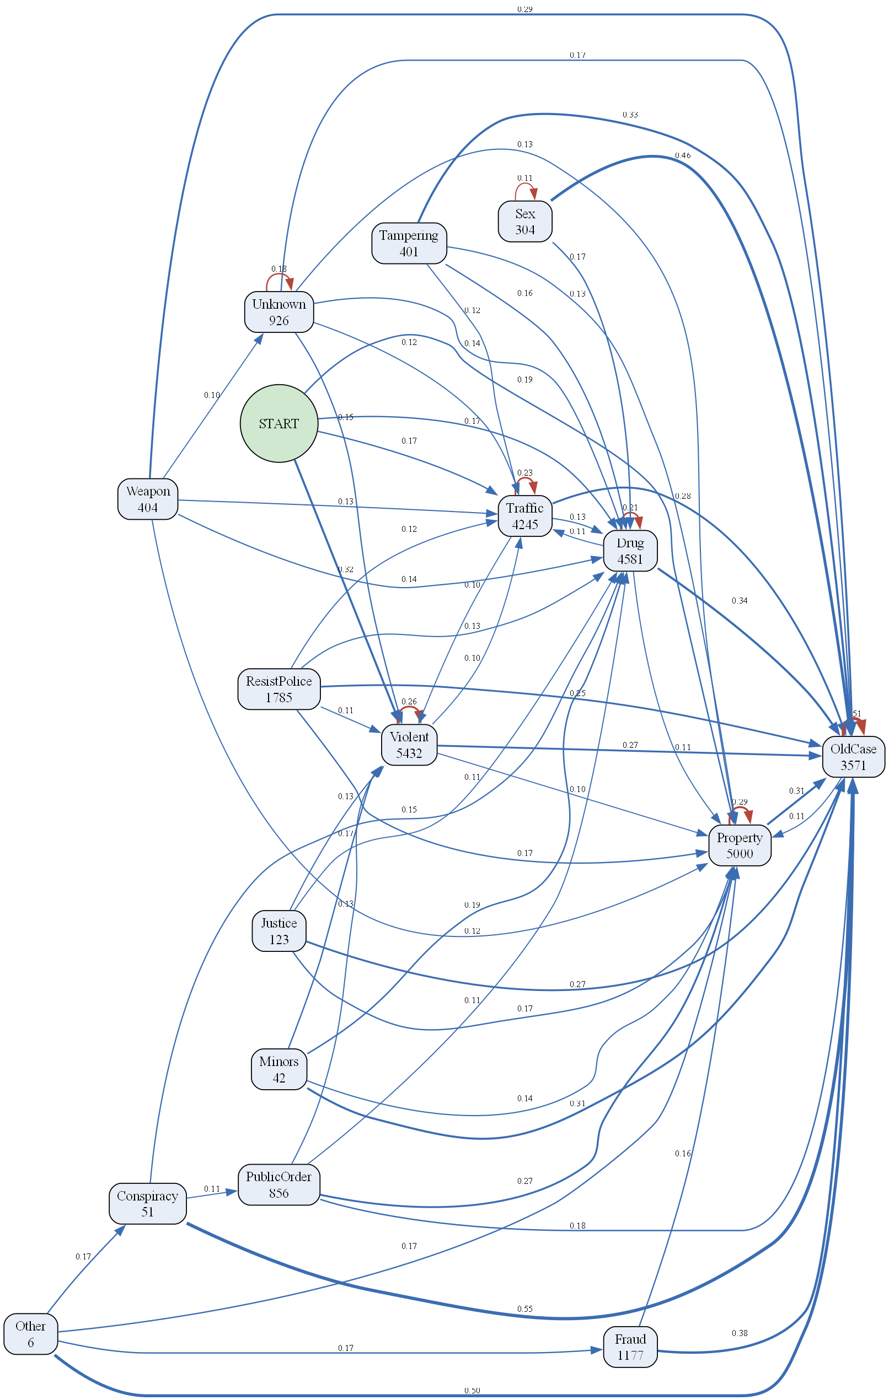

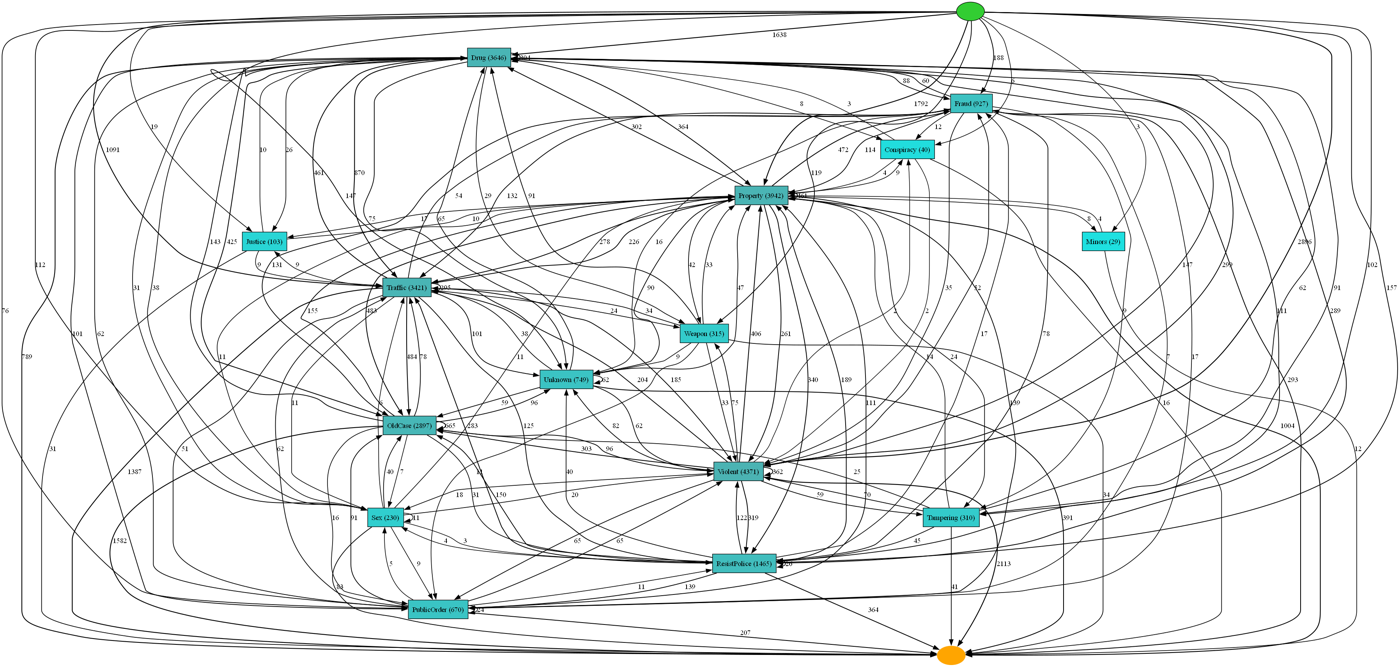

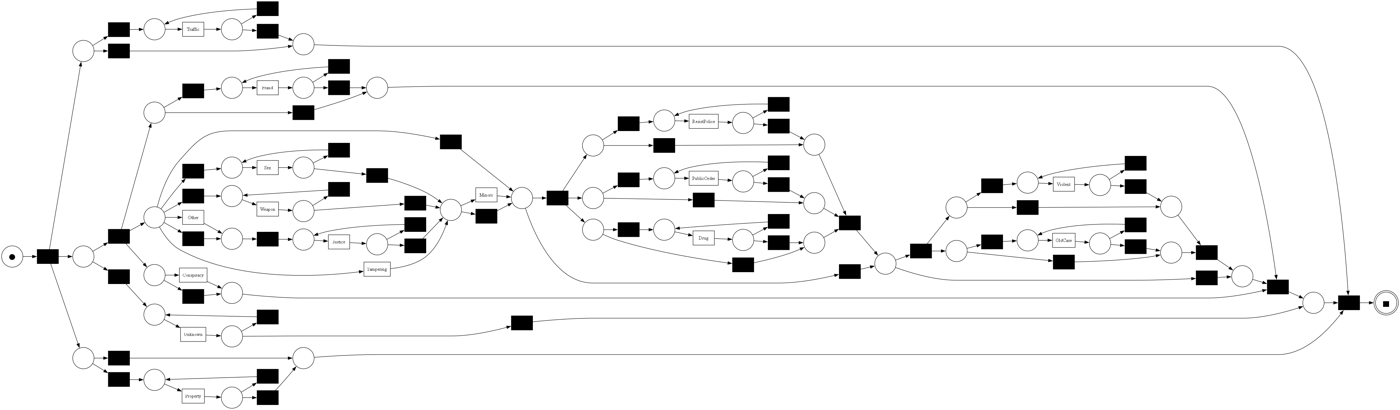

dst,Violent,Property,Drug,Traffic,OldCase,ResistPolice,Fraud,Unknown,PublicOrder,Weapon,Tampering,Sex,Justice,Conspiracy,Minors,Other
src,,,,,,,,,,,,,,,,
START,0.32,0.19,0.17,0.17,0.00,0.04,0.04,0.02,0.02,0.01,0.01,0.01,0.00,0.00,0.00,0.0
Violent,0.26,0.10,0.09,0.10,0.27,0.04,0.02,0.07,0.02,0.01,0.00,0.00,0.00,0.00,0.00,0.0
Property,0.07,0.29,0.09,0.07,0.31,0.03,0.03,0.06,0.03,0.00,0.00,0.01,0.00,0.00,0.00,0.0
Drug,0.07,0.11,0.21,0.11,0.34,0.03,0.02,0.06,0.02,0.01,0.01,0.01,0.00,0.00,0.00,0.0
Traffic,0.10,0.10,0.13,0.23,0.28,0.03,0.02,0.06,0.01,0.01,0.01,0.00,0.00,0.00,0.00,0.0
OldCase,0.07,0.11,0.09,0.07,0.51,0.03,0.01,0.07,0.02,0.01,0.00,0.01,0.00,0.00,0.00,0.0
ResistPolice,0.11,0.17,0.13,0.12,0.25,0.07,0.03,0.07,0.03,0.01,0.01,0.00,0.00,0.00,0.00,0.0
Fraud,0.06,0.16,0.09,0.10,0.38,0.04,0.07,0.06,0.02,0.01,0.01,0.01,0.01,0.00,0.00,0.0
Unknown,0.15,0.13,0.14,0.12,0.17,0.03,0.02,0.18,0.04,0.01,0.01,0.01,0.01,0.00,0.00,0.0


In [28]:
# ============================== Этап 1.3.A. Граф переходов: все обвинения заключения ==============================
# Переход - пара соседних шагов человека S_k -> S_{k+1}. При развилках каждая пара типов (a из S_k, b из S_{k+1})
# получает вес 1 / (|S_k| |S_{k+1}|), один переход в сумме весит 1. p(a -> b) = вес / вес всех переходов из a.
# START - распределение первого шага. Последний шаг человека цензурирован и в вероятности не входит.
steps["next_types"] = steps.groupby("id")["type_list"].shift(-1)
steps["next_reason"] = steps.groupby("id")["reason"].shift(-1)

def transition_pairs(s):
    d = s[s["next_types"].notna()].copy()
    d["tr_id"] = np.arange(len(d))
    d["w"] = 1.0 / (d["type_list"].str.len() * d["next_types"].str.len())
    d = d.assign(src=d["type_list"]).explode("src").assign(dst=lambda x: x["next_types"]).explode("dst")
    first = s[s["event_idx"] == 1]
    st0 = first.assign(src=START, dst=first["type_list"], w=1.0 / first["type_list"].str.len()).explode("dst")
    return pd.concat([st0, d], ignore_index=True)

def transition_matrix(s, order):
    """пары переходов, матрица вероятностей P (строки - START и типы, столбцы - типы) и число пар N"""
    pairs = transition_pairs(s)
    W = pd.crosstab(pairs["src"], pairs["dst"], values=pairs["w"], aggfunc="sum").fillna(0)
    W = W.reindex(index=[START] + order, columns=order, fill_value=0)
    P = W.div(W.sum(axis=1), axis=0)
    N = pd.crosstab(pairs["src"], pairs["dst"]).reindex(index=[START] + order, columns=order, fill_value=0)
    return pairs, P, N

def draw_graph(P, path, min_p=0.10, counts=None):
    import graphviz
    g = graphviz.Digraph(format="png", graph_attr=dict(rankdir="LR", dpi="130"),
                         node_attr=dict(shape="box", style="rounded,filled", fillcolor="#e8eef7"),
                         edge_attr=dict(fontsize="9"))
    g.node(START, shape="circle", fillcolor="#cfe8cf")
    if counts is not None:
        for a, n in counts.items():
            g.node(a, f"{a}\n{n}")
    for a in P.index:
        for b in P.columns:
            p = P.loc[a, b]
            if p >= min_p:
                g.edge(a, b, label=f"{p:.2f}", penwidth=f"{0.5 + 5 * p:.2f}", color="#b3473b" if a == b else "#3b6db3")
    g.render(str(path), cleanup=True)
    return str(path) + ".png"

def show_graphs(P, counts, heuristics_net, inductive, suffix=""):
    """граф переходов, эвристическая сеть и индуктивная сеть Петри"""
    try:
        show(draw_graph(P, STAGES / f"transition_graph{suffix}", counts=counts))
        pm4py.save_vis_heuristics_net(heuristics_net, str(STAGES / f"heuristics_net{suffix}.png"))
        show(STAGES / f"heuristics_net{suffix}.png")
        pm4py.save_vis_petri_net(*inductive, str(STAGES / f"petri_inductive{suffix}.png"))
        show(STAGES / f"petri_inductive{suffix}.png")
    except Exception as e:                                                  # нет graphviz / dot
        print("рисунок не построен:", e)

pairs, P, N = transition_matrix(steps, labels)
counts_A = steps["type_list"].explode().value_counts()                     # заключений с этим типом
P.round(4).to_csv(STAGES / "transition_probs.csv")
print("A: дуг с p >= 0.10:", int((P >= 0.10).sum().sum()), "| с p >= 0.05:", int((P >= 0.05).sum().sum()))
show_graphs(P, counts_A, hn, models["Inductive noise=0.2"])
P.round(2)


#### B. Одно обвинение на заключение

Шаг — основной тип заключения, вес каждого перехода 1. Типы, которые ни разу не были основными, в матрицу не входят.


B: дуг с p >= 0.10: 59 | с p >= 0.05: 85


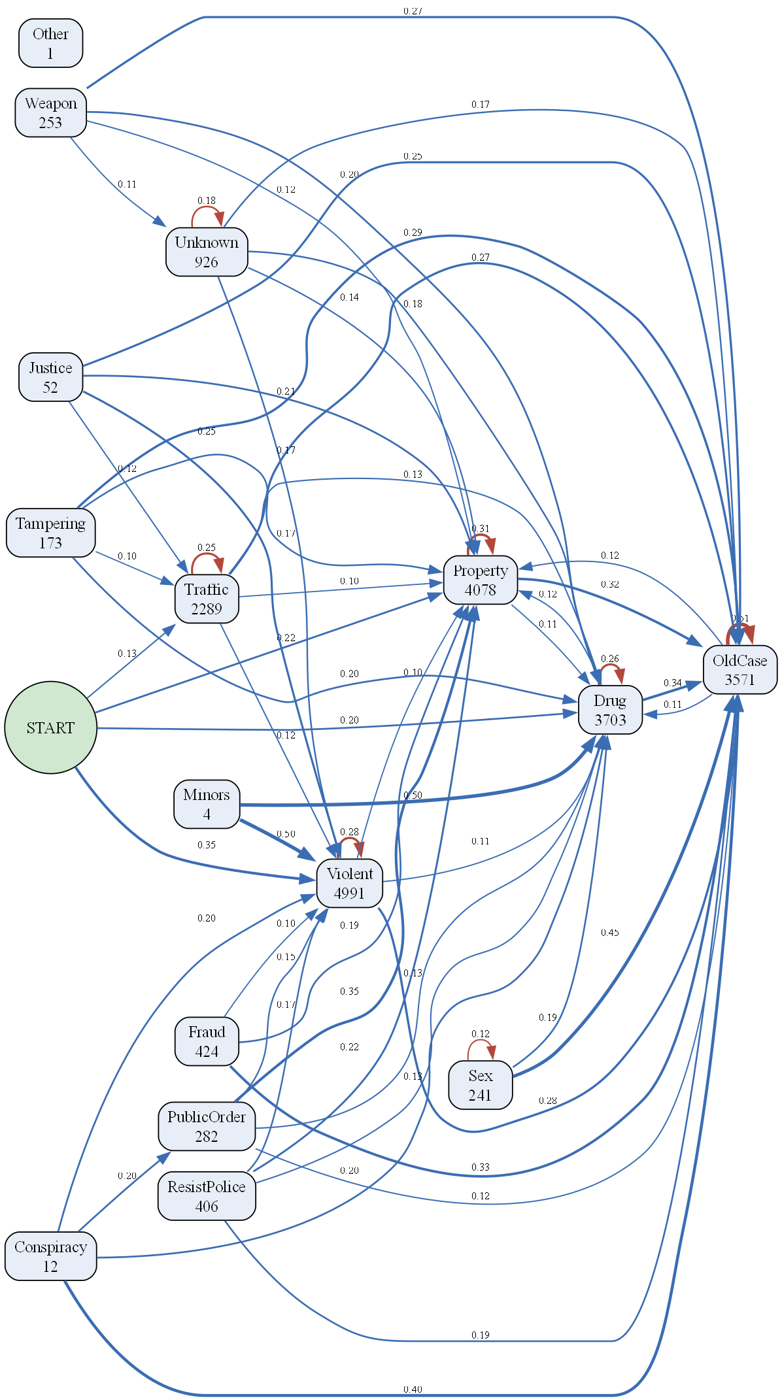

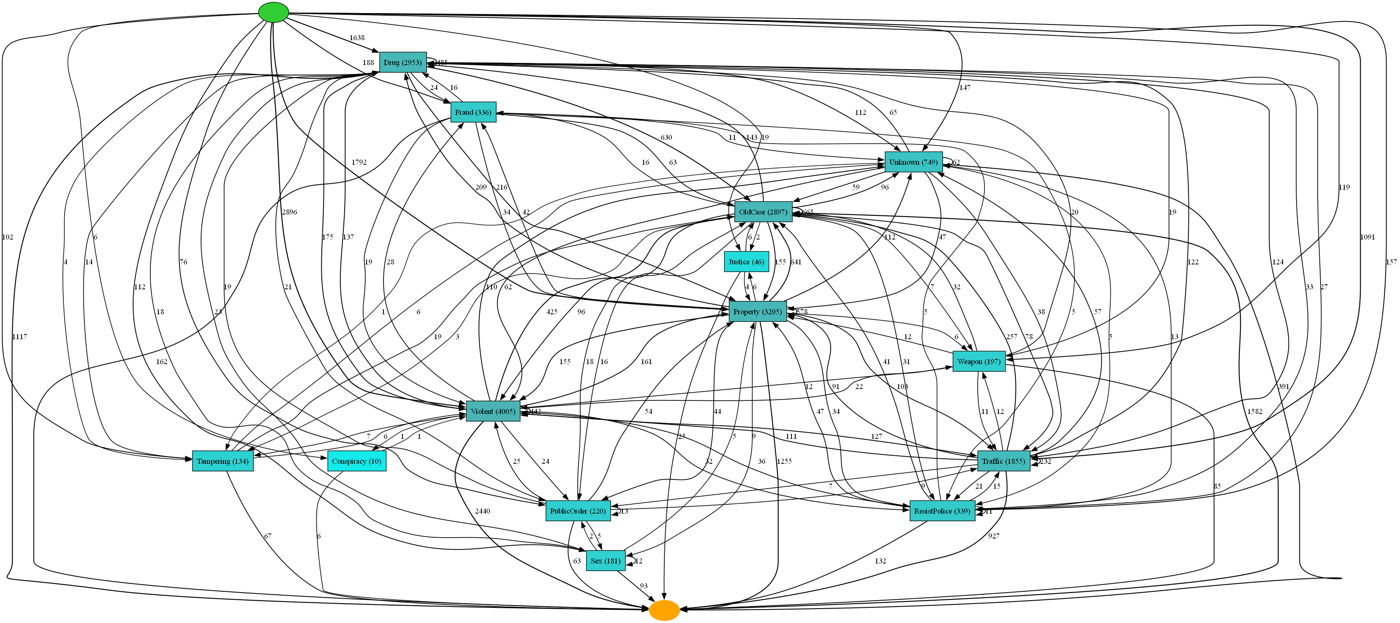

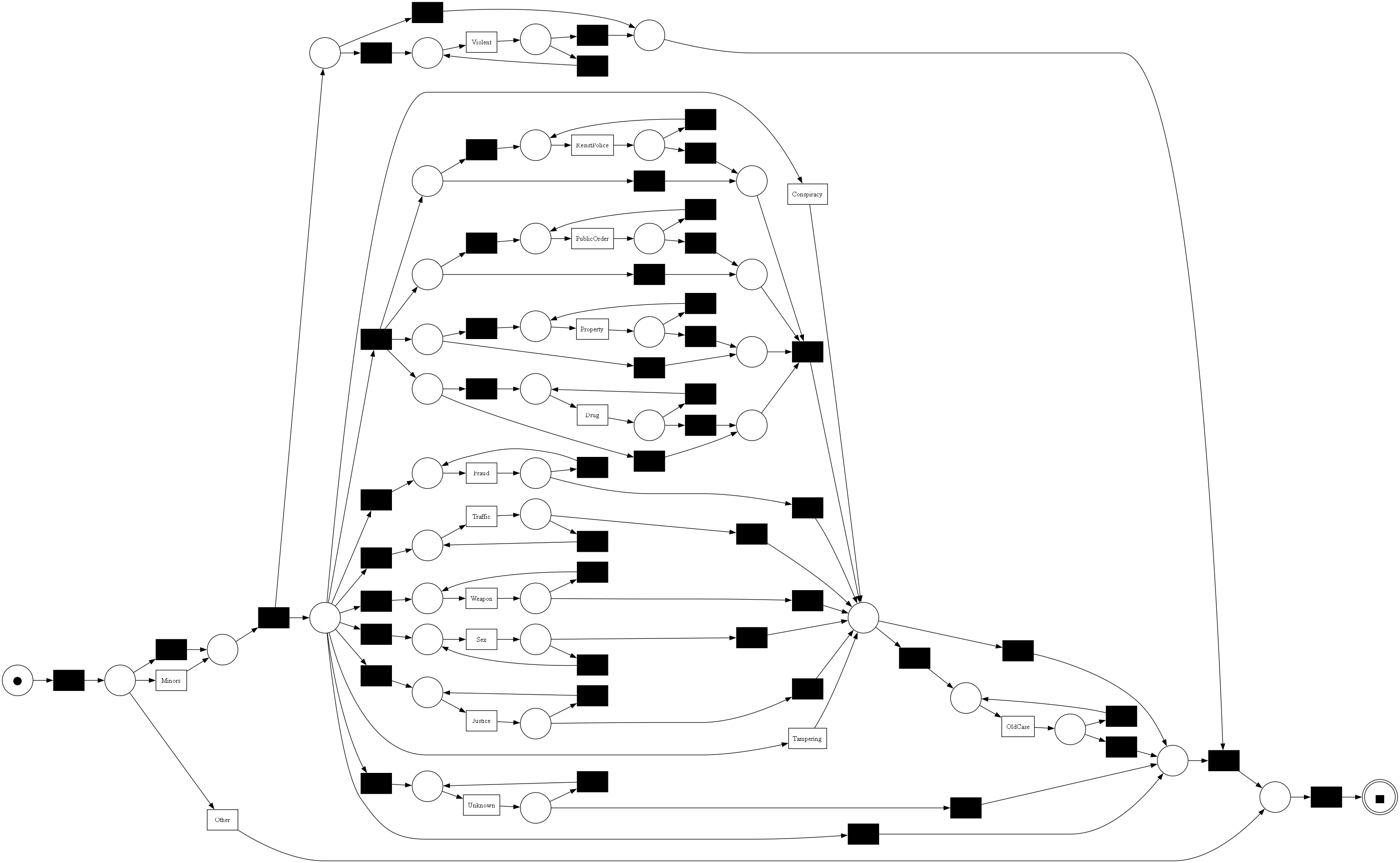

dst,Violent,Property,Drug,Traffic,OldCase,ResistPolice,Fraud,Unknown,PublicOrder,Weapon,Tampering,Sex,Justice,Conspiracy,Minors,Other
src,,,,,,,,,,,,,,,,
START,0.35,0.22,0.20,0.13,0.00,0.02,0.02,0.02,0.01,0.01,0.01,0.02,0.00,0.0,0.0,0.0
Violent,0.28,0.10,0.11,0.08,0.28,0.02,0.02,0.07,0.02,0.01,0.00,0.00,0.00,0.0,0.0,0.0
Property,0.08,0.31,0.11,0.05,0.32,0.02,0.02,0.06,0.02,0.00,0.00,0.01,0.00,0.0,0.0,0.0
Drug,0.08,0.12,0.26,0.07,0.34,0.02,0.01,0.06,0.01,0.01,0.00,0.01,0.00,0.0,0.0,0.0
Traffic,0.12,0.10,0.13,0.25,0.27,0.02,0.01,0.06,0.01,0.01,0.00,0.00,0.00,0.0,0.0,0.0
OldCase,0.08,0.12,0.11,0.06,0.51,0.02,0.01,0.07,0.01,0.01,0.00,0.00,0.00,0.0,0.0,0.0
ResistPolice,0.17,0.22,0.13,0.07,0.19,0.05,0.03,0.07,0.03,0.01,0.02,0.00,0.00,0.0,0.0,0.0
Fraud,0.10,0.19,0.10,0.08,0.33,0.03,0.06,0.07,0.01,0.01,0.00,0.00,0.01,0.0,0.0,0.0
Unknown,0.17,0.14,0.18,0.10,0.17,0.02,0.01,0.18,0.03,0.01,0.00,0.01,0.00,0.0,0.0,0.0


In [29]:
# ============================== Этап 1.3.B. Граф переходов: одно обвинение на заключение ==============================
# Шаг - основной тип заключения (самый тяжёлый, первый в types_by_severity), вес каждого перехода 1.
steps_B = steps.assign(type_list=steps["types_by_severity"].str.split("+").str[:1])
steps_B["next_types"] = steps_B.groupby("id")["type_list"].shift(-1)
counts_B = steps_B["type_list"].explode().value_counts()                   # заключений с этим основным типом
labels_B = [s for s in labels if s in counts_B.index]
pairs_B, P_B, N_B = transition_matrix(steps_B, labels_B)
P_B.round(4).to_csv(STAGES / "transition_probs_B.csv")
print("B: дуг с p >= 0.10:", int((P_B >= 0.10).sum().sum()), "| с p >= 0.05:", int((P_B >= 0.05).sum().sum()))
hn_B = pm4py.discover_heuristics_net(train_main, dependency_threshold=0.9)
show_graphs(P_B, counts_B, hn_B, models_main["Inductive noise=0.2"], suffix="_B")
P_B.round(2)


### 1.4. Причины переходов

Для A и для B:
1. **причина следующего заключения** в зависимости от текущего типа: `new_offense` (новое дело), `rearrest_old_case` (повторное заключение по старому делу), `transfer_unlinked` (перевод без дела), не привязано. Доли — по весу переходов;
2. **профиль 15 самых частых переходов**: `p` из 1.3, число переходов, медиана дней на свободе до следующего заключения и средние по заключениям-источникам (возраст, доля мужчин, балл COMPAS, доля felony, дней в заключении), взвешенные по переходам.

В конце — сравнение A и B и выводы.

#### A. Все обвинения заключения


In [30]:
# ============================== Этап 1.4.A. Причины переходов: все обвинения заключения ==============================
# Причина перехода - причина следующего заключения (reason): новое дело (new_offense), повторный арест по старому делу
# (rearrest_old_case), перевод без дела (transfer_unlinked), не привязано. Доли - по весу переходов.
# Причина однозначно задаётся следующим состоянием (OldCase - старое дело, типы преступлений - новое дело), поэтому
# по дугам смотрим не причину, а с чем переход связан: профиль эпизодов-источников самых частых дуг
# (возраст, пол, балл COMPAS, тяжесть, длительность заключения) и дни на свободе до перехода.
def reason_tables(pairs, steps, P, order, n_top=15):
    reasons = pairs[pairs["src"] != START].copy()
    reasons["next_reason"] = reasons["next_reason"].fillna("не привязано")
    by_state = (pd.crosstab(reasons["src"], reasons["next_reason"], values=reasons["w"], aggfunc="sum", normalize="index")
                  .reindex(order).dropna(how="all"))
    src_ep = steps.drop_duplicates(["id", "ep_row"], keep="last").set_index(["id", "ep_row"])
    r = reasons.join(src_ep[["deg_rank", "dur"]].rename(columns=lambda c: "src_" + c), on=["id", "ep_row"])
    r["male"] = (r["sex"] == "Male").astype(float)
    r["felony"] = (r["src_deg_rank"] <= 4).astype(float)
    wsum = r.groupby(["src", "dst"])["w"].sum()
    top_arcs = wsum.nlargest(n_top).index
    wavg = lambda g, c: np.average(g[c], weights=g["w"])
    arc_profile = pd.DataFrame({
        "p": [P.loc[a, b] for a, b in top_arcs],
        "переходов (вес)": wsum.loc[top_arcs].round(0).values,
        "медиана дней": [r[(r["src"] == a) & (r["dst"] == b)]["gap_next"].median() for a, b in top_arcs],
        **{name: [wavg(r[(r["src"] == a) & (r["dst"] == b)], c) for a, b in top_arcs]
           for name, c in [("возраст", "age"), ("доля мужчин", "male"), ("балл COMPAS", "decile_score"),
                           ("доля felony", "felony"), ("дней в заключении", "src_dur")]}},
        index=top_arcs).round(3)
    return by_state, arc_profile

by_state, arc_profile = reason_tables(pairs, steps, P, labels)
by_state.round(4).to_csv(STAGES / "transition_reasons_by_state.csv")
arc_profile.to_csv(STAGES / "transition_profiles.csv")
print("A. Причина следующего заключения в зависимости от текущего состояния:")
display(by_state.round(3))
print("A. 15 самых частых переходов: профиль эпизода-источника (средние, взвешенные по переходам):")
arc_profile


A. Причина следующего заключения в зависимости от текущего состояния:


next_reason,new_offense,rearrest_old_case,transfer_unlinked,не привязано
src,,,,
Violent,0.677,0.269,0.003,0.051
Property,0.637,0.313,0.001,0.049
Drug,0.611,0.338,0.002,0.048
Traffic,0.662,0.285,0.001,0.052
OldCase,0.435,0.507,0.000,0.058
ResistPolice,0.695,0.250,0.001,0.055
Fraud,0.561,0.384,0.002,0.053
Unknown,0.671,0.167,0.000,0.162
PublicOrder,0.795,0.182,0.000,0.023


A. 15 самых частых переходов: профиль эпизода-источника (средние, взвешенные по переходам):


p  переходов (вес)  медиана дней  возраст  доля мужчин  \
src      dst                                                                    
OldCase  OldCase   0.507            818.0         104.0   29.314        0.836   
Property OldCase   0.312            688.0         142.0   29.638        0.816   
Drug     OldCase   0.338            643.0         135.0   31.457        0.826   
Property Property  0.287            633.0          81.0   32.538        0.833   
Violent  OldCase   0.269            458.0         138.5   30.807        0.842   
         Violent   0.264            450.0         125.0   32.933        0.820   
Traffic  OldCase   0.285            439.0         146.0   32.661        0.843   
Drug     Drug      0.213            406.0         106.0   30.508        0.839   
Traffic  Traffic   0.231            356.0         137.5   31.804        0.888   
Drug     Property  0.110            209.0          88.5   30.611        0.873   
         Traffic   0.107            203.0         133.5   29.395        0.896   
Property Drug      0.090            199.0         100.0   29.731        0.870   
Traffic  Drug      0.128            197.0         122.0   28.912        0.883   
Violent  Property  0.102            174.0         135.0   29.491        0.798   
         Traffic   0.102            173.0         198.5   29.310        0.840   

                   балл COMPAS  доля felony  дней в заключении  
src      dst                                                    
OldCase  OldCase         6.165        0.864             35.961  
Property OldCase         5.932        0.864             37.279  
Drug     OldCase         5.977        0.891             21.622  
Property Property        6.516        0.664             33.862  
Violent  OldCase         5.235        0.690             39.790  
         Violent         4.874        0.363             22.355  
Traffic  OldCase         5.236        0.580             17.083  
Drug     Drug            6.439        0.827             22.043  
Traffic  Traffic         5.150        0.504              7.716  
Drug     Property        6.916        0.771             34.635  
         Traffic         6.387        0.755             15.685  
Property Drug            6.570        0.656             28.791  
Traffic  Drug            6.470        0.584             16.281  
Violent  Property        5.975        0.489             39.051  
         Traffic         5.380        0.481             22.588

#### B. Одно обвинение на заключение

Те же таблицы для основного типа заключения (матрица `P_B` из 1.3.B).


In [31]:
# ============================== Этап 1.4.B. Причины переходов: одно обвинение на заключение ==============================
by_state_B, arc_profile_B = reason_tables(pairs_B, steps_B, P_B, labels_B)
by_state_B.round(4).to_csv(STAGES / "transition_reasons_by_state_B.csv")
arc_profile_B.to_csv(STAGES / "transition_profiles_B.csv")
print("B. Причина следующего заключения в зависимости от текущего состояния:")
display(by_state_B.round(3))
print("B. 15 самых частых переходов: профиль эпизода-источника:")
arc_profile_B


B. Причина следующего заключения в зависимости от текущего состояния:


next_reason,new_offense,rearrest_old_case,transfer_unlinked,не привязано
src,,,,
Violent,0.668,0.277,0.003,0.053
Property,0.631,0.320,0.000,0.049
Drug,0.615,0.337,0.002,0.046
Traffic,0.678,0.269,0.001,0.052
OldCase,0.435,0.507,0.000,0.058
ResistPolice,0.751,0.191,0.000,0.058
Fraud,0.613,0.330,0.005,0.052
Unknown,0.671,0.167,0.000,0.162
PublicOrder,0.866,0.119,0.000,0.015


B. 15 самых частых переходов: профиль эпизода-источника:


p  переходов (вес)  медиана дней  возраст  доля мужчин  \
src      dst                                                                    
OldCase  OldCase   0.507            818.0         104.0   29.314        0.836   
Property OldCase   0.319            792.0         148.0   28.894        0.824   
         Property  0.312            775.0          80.0   31.666        0.837   
Drug     OldCase   0.337            768.0         130.0   31.857        0.822   
         Drug      0.265            603.0         106.0   30.698        0.842   
Violent  Violent   0.281            552.0         123.5   32.453        0.824   
         OldCase   0.277            545.0         132.0   30.806        0.837   
Traffic  OldCase   0.269            310.0         142.5   33.877        0.845   
         Traffic   0.252            290.0         140.0   33.238        0.883   
Drug     Property  0.118            269.0          94.0   30.725        0.888   
Property Drug      0.106            263.0         105.0   29.962        0.875   
Violent  Drug      0.110            216.0         165.0   29.028        0.898   
         Property  0.104            205.0         133.0   29.385        0.800   
Property Violent   0.078            193.0         120.0   28.244        0.839   
OldCase  Property  0.115            186.0         107.0   30.108        0.796   

                   балл COMPAS  доля felony  дней в заключении  
src      dst                                                    
OldCase  OldCase         6.165        0.864             35.961  
Property OldCase         5.880        0.885             39.126  
         Property        6.530        0.702             32.741  
Drug     OldCase         6.000        0.893             20.382  
         Drug            6.599        0.836             22.118  
Violent  Violent         5.045        0.382             26.547  
         OldCase         5.382        0.703             41.749  
Traffic  OldCase         4.997        0.458             18.829  
         Traffic         4.841        0.493              7.134  
Drug     Property        6.803        0.773             35.732  
Property Drug            6.490        0.662             28.483  
Violent  Drug            6.176        0.546             27.546  
         Property        6.107        0.502             46.459  
Property Violent         6.326        0.663             27.218  
OldCase  Property        6.731        0.624             32.473

#### Сравнение A и B

Три таблицы:
1. **качество моделей:** `f1` в A по цепочке событий (1.2.A), `f1_types` в A по парам соседних заключений и `f1` в B;
2. **состояния** (основной тип не реже 100 раз): сколько заключений, вероятность повтора того же типа, вероятность перейти в `OldCase` и доля новых дел среди следующих заключений — в A и в B;
3. **частые дуги** (10 самых частых в A и 10 в B): `p` и число переходов в каждом варианте.

Результаты — `compare_quality.csv`, `compare_states.csv`, `compare_arcs.csv`.


In [32]:
# ============================== Этап 1.4. Сравнение A и B ==============================
q_cmp = pd.DataFrame({"A: f1 (цепочка событий)": quality["f1"], "A: f1_types (пары заключений)": quality_steps["f1_types"],
                      "B: f1": quality_main["f1"]})
q_cmp.to_csv(STAGES / "compare_quality.csv")
print("Качество моделей:")
display(q_cmp)

st = [s for s in labels_B if counts_B[s] >= 100]
pget = lambda M, a, b: M.loc[a, b] if a in M.index and b in M.columns else np.nan
s_cmp = pd.DataFrame({
    "заключений A": counts_A.reindex(st), "заключений B": counts_B.reindex(st),
    "повтор A": [pget(P, s, s) for s in st], "повтор B": [pget(P_B, s, s) for s in st],
    "-> OldCase A": [pget(P, s, "OldCase") for s in st], "-> OldCase B": [pget(P_B, s, "OldCase") for s in st],
    "новое дело A": by_state.reindex(st).get("new_offense"), "новое дело B": by_state_B.reindex(st).get("new_offense"),
}, index=st).round(3)
s_cmp.to_csv(STAGES / "compare_states.csv")
print("Состояния (основной тип не реже 100 раз):")
display(s_cmp)

wA = pairs[pairs["src"] != START].groupby(["src", "dst"])["w"].sum()
wB = pairs_B[pairs_B["src"] != START].groupby(["src", "dst"])["w"].sum()
top = wA.nlargest(10).index.union(wB.nlargest(10).index)
a_cmp = pd.DataFrame({"p A": [pget(P, a, b) for a, b in top], "p B": [pget(P_B, a, b) for a, b in top],
                      "переходов A": wA.reindex(top).round(0).values, "переходов B": wB.reindex(top).round(0).values},
                     index=top)
a_cmp["p B - p A"] = a_cmp["p B"] - a_cmp["p A"]
a_cmp = a_cmp.sort_values("переходов A", ascending=False).round(3)
a_cmp.index.names = ["from", "to"]
a_cmp.to_csv(STAGES / "compare_arcs.csv")
print("Частые дуги:")
a_cmp


Качество моделей:


,A: f1 (цепочка событий),A: f1_types (пары заключений),B: f1
model,,,
DFG p>=0.0,0.7694,0.9608,0.8756
DFG p>=0.02,0.8736,0.9690,0.9454
DFG p>=0.05,0.9042,0.9395,0.9567
DFG p>=0.1,0.9115,0.9097,0.9593
Heuristics dep=0.9,0.8458,0.9721,0.9016
Inductive noise=0.2,0.8492,0.9127,0.9194
Шаги p>=0.0,NaN,0.9565,NaN
Шаги p>=0.02,NaN,0.9535,NaN
Шаги p>=0.05,NaN,0.8805,NaN


Состояния (основной тип не реже 100 раз):


,заключений A,заключений B,повтор A,повтор B,-> OldCase A,-> OldCase B,новое дело A,новое дело B
Violent,5432,4991,0.264,0.281,0.269,0.277,0.677,0.668
Property,5000,4078,0.287,0.312,0.312,0.319,0.637,0.631
Drug,4581,3703,0.213,0.265,0.338,0.337,0.611,0.615
Traffic,4245,2289,0.231,0.252,0.285,0.269,0.662,0.678
OldCase,3571,3571,0.507,0.507,0.507,0.507,0.435,0.435
ResistPolice,1785,406,0.071,0.050,0.250,0.191,0.695,0.751
Fraud,1177,424,0.069,0.057,0.384,0.330,0.561,0.613
Unknown,926,926,0.175,0.175,0.167,0.167,0.671,0.671
PublicOrder,856,282,0.089,0.079,0.182,0.119,0.795,0.866
Weapon,404,253,0.029,0.035,0.288,0.266,0.613,0.629


Частые дуги:


p A    p B  переходов A  переходов B  p B - p A
from     to                                                         
OldCase  OldCase   0.507  0.507        818.0        818.0      0.000
Property OldCase   0.312  0.319        688.0        792.0      0.007
Drug     OldCase   0.338  0.337        643.0        768.0     -0.001
Property Property  0.287  0.312        633.0        775.0      0.025
Violent  OldCase   0.269  0.277        458.0        545.0      0.008
         Violent   0.264  0.281        450.0        552.0      0.016
Traffic  OldCase   0.285  0.269        439.0        310.0     -0.016
Drug     Drug      0.213  0.265        406.0        603.0      0.051
Traffic  Traffic   0.231  0.252        356.0        290.0      0.021
Drug     Property  0.110  0.118        209.0        269.0      0.008

#### Выводы этапа 1 (A и B)

Числа — по прогону 20.11.2026; при пересчёте сверяйте с таблицами выше.

**1. Качество моделей.** По метрикам PM4Py модели B лучше: лучший `f1` в B — 0.959 (`DFG p>=0.1`) и 0.957 (`DFG p>=0.05`), в A — 0.912. Но если оценивать A по парам соседних заключений (`f1_types`), A не хуже: 0.972 у эвристической сети и 0.969 у `DFG p>=0.02`. Значит, низкий `f1` A по цепочке событий в основном связан с тем, как цепочка записывает развилки, а не со структурой переходов. Цифры A и B сравнимы лишь отчасти: тестовые журналы разные.

**2. Структура переходов почти одинакова.** Для основных состояний вероятности в A и B отличаются не больше чем на 0.05. Самые частые дуги в обоих вариантах — повтор того же типа и переход в `OldCase`.

**3. Повтор типа в B немного выше.** Violent 0.265 → 0.281, Property 0.285 → 0.311, Drug 0.213 → 0.264, Traffic 0.231 → 0.252. В A вес перехода из развилки делится между её типами, поэтому повтор размывается; сильнее всего у Drug, который часто идёт вместе с Traffic и Property.

**4. Сопутствующие типы в B почти исчезают.** ResistPolice: 1 785 заключений в A → 406 основных в B, PublicOrder 856 → 282, Tampering 401 → 173, Fraud 1 178 → 424, Traffic 4 246 → 2 290. Эти обвинения чаще всего идут вместе с более тяжёлым. B описывает переходы между основными преступлениями, A — между всеми обвинениями. Когда такие типы всё же основные, следующее заключение чаще по новому делу: ResistPolice → `OldCase` 0.249 в A и 0.191 в B, PublicOrder 0.183 и 0.119.



## Этап 2. Параметры переходов

Вариант B: состояние эпизода — основной тип заключения (самый тяжёлый, 1.1.B), вероятности переходов — `P_B` из 1.3.B. Каждый эпизод попадает ровно в одно состояние, поэтому развилки не считаются несколько раз.

### 2.1. Эпизоды на свободе

In [33]:
# ============================== Этап 2.1. Эпизоды на свободе (вариант B) ==============================
# Состояние эпизода - основной тип заключения (steps_B, 1.3.B).
# Время перехода - дни на свободе от выхода из заключения до следующего входа (по эпизодам). Последний эпизод человека цензурирован на 01.04.2016 (followup_days).
# Не используются: ещё сидят на конец наблюдения (выхода нет) и пересекающиеся заключения (отрицательный разрыв).
ep = (steps_B.groupby(["id", "ep_row"], sort=False)
           .agg(in_custody=("in_custody", "first"), out_custody=("out_custody", "last"),
                types=("type_list", lambda s: sorted(set(sum(s, [])))), reason=("reason", "first"),
                censored=("censored", "last"), gap_next=("gap_next", "last"), followup_days=("followup_days", "last"),
                ongoing=("ongoing", "max"), age=("age", "first"), sex=("sex", "first"), decile_score=("decile_score", "first"),
                deg_rank=("deg_rank", "min"), dur=("dur", "max"), is_test=("is_test", "first"))
           .reset_index())
ep["next_types"] = ep.groupby("id")["types"].shift(-1)
ep["T"] = np.where(ep["censored"], ep["followup_days"], ep["gap_next"])
ep["E"] = (~ep["censored"]).astype(int)
n0 = len(ep)
ep = ep[~ep["ongoing"] & (ep["T"] >= 0)].copy()
ep["T"] = ep["T"].clip(lower=0.5)                                       # повторный вход в день выхода - полдня
print(f"эпизодов: {n0}, для моделей времени: {len(ep)} (убраны ещё сидящие и пересечения: {n0 - len(ep)}); "
      f"переход наблюдался у {ep['E'].sum()}, цензурировано {len(ep) - ep['E'].sum()}")
ep_x = ep.explode("types").rename(columns={"types": "state"})            # один основной тип на эпизод

эпизодов: 21406, для моделей времени: 20671 (убраны ещё сидящие и пересечения: 735); переход наблюдался у 10941, цензурировано 9730


### 2.2. Распределения времени до следующего заключения

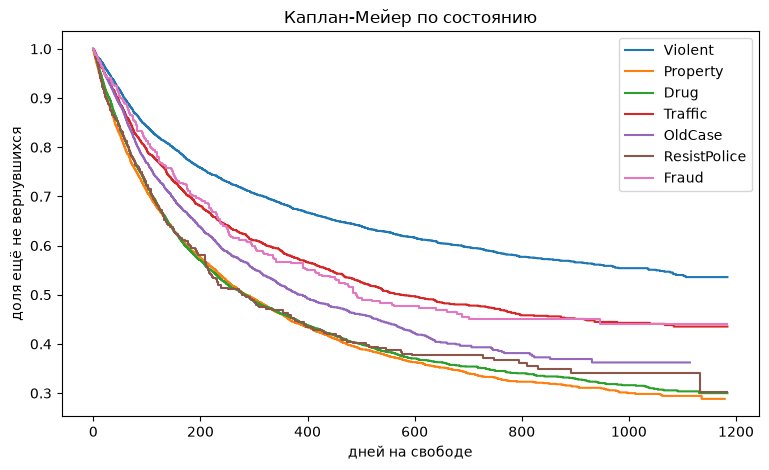

,episodes,transitions,km_median_days,p_next_within_1y,AIC_exp,AIC_weibull,weibull_lambda,weibull_rho,AIC_lognorm,lognorm_mu,lognorm_sigma,best
state,,,,,,,,,,,,
Violent,4910,1964,inf,0.320,32126.7,31537.9,1987.6,0.633,31384.7,7.134,2.428,lognorm
Property,3926,2470,285.0,0.550,36199.8,35479.6,602.3,0.654,35313.1,5.730,2.058,lognorm
Drug,3645,2276,282.0,0.544,33568.3,32933.9,631.9,0.661,32692.9,5.780,1.986,lognorm
Traffic,2274,1150,575.0,0.420,17940.3,17626.6,1124.6,0.654,17515.3,6.442,2.167,lognorm
OldCase,3340,1603,386.0,0.489,23650.3,23481.7,670.9,0.769,23360.1,6.009,1.857,lognorm
ResistPolice,402,241,284.0,0.541,3569.1,3490.4,667.4,0.638,3459.7,5.816,2.051,lognorm
Fraud,410,209,491.0,0.434,3240.7,3197.6,1035.7,0.684,3183.3,6.398,2.104,lognorm
Unknown,777,456,245.0,0.631,6335.3,6332.2,385.1,0.920,6342.6,5.443,1.501,weibull
PublicOrder,277,201,145.0,0.708,2739.3,2657.4,310.3,0.624,2629.6,4.969,1.934,lognorm


In [34]:
# ============================== Этап 2.2. Распределения времени до следующего заключения ==============================
# Полумарковская модель: из состояния a следующий переход происходит через время T ~ F_a (с учётом цензуры),
# в состояние b - с вероятностью P_B[a, b] (этап 1.3.B). Для F_a сравниваются экспоненциальное, Вейбулла и логнормальное
# распределения (lifelines, максимальное правдоподобие с цензурой); лучшее - по AIC. Медиана Каплана-Мейера - для сравнения.
from lifelines import KaplanMeierFitter, ExponentialFitter, WeibullFitter, LogNormalFitter
import matplotlib.pyplot as plt

rows = []
for s in labels_B:
    d = ep_x[ep_x["state"] == s]
    if d["E"].sum() < 20:
        continue
    km = KaplanMeierFitter().fit(d["T"], d["E"])
    r = dict(state=s, episodes=len(d), transitions=int(d["E"].sum()), km_median_days=km.median_survival_time_,
             p_next_within_1y=round(1 - float(km.survival_function_at_times(365).iloc[0]), 3))
    for name, F in (("exp", ExponentialFitter), ("weibull", WeibullFitter), ("lognorm", LogNormalFitter)):
        f = F().fit(d["T"], d["E"])
        r[f"AIC_{name}"] = round(f.AIC_, 1)
        if name == "weibull":
            r["weibull_lambda"], r["weibull_rho"] = round(f.lambda_, 1), round(f.rho_, 3)
        if name == "lognorm":
            r["lognorm_mu"], r["lognorm_sigma"] = round(f.mu_, 3), round(f.sigma_, 3)
    r["best"] = min(("exp", "weibull", "lognorm"), key=lambda n: r[f"AIC_{n}"])
    rows.append(r)
time_dist = pd.DataFrame(rows).set_index("state")
time_dist.to_csv(STAGES / "time_distributions.csv")

fig, ax = plt.subplots(figsize=(9, 5))
for s in labels_B[:7]:
    d = ep_x[ep_x["state"] == s]
    KaplanMeierFitter().fit(d["T"], d["E"], label=s).plot_survival_function(ax=ax, ci_show=False)
ax.set_xlabel("дней на свободе"); ax.set_ylabel("доля ещё не вернувшихся"); ax.set_title("Каплан-Мейер по состоянию")
plt.show()
time_dist

### 2.3. Время по дугам

In [35]:
# ============================== Этап 2.3. Время по дугам ==============================
# Для каждой дуги a -> b: вероятность P_B[a, b] (1.3.B), число переходов, медиана и квартили дней на свободе (наблюдённые переходы).
arc_t = ep_x[ep_x["E"] == 1].assign(dst=lambda x: x["next_types"]).explode("dst")
g = arc_t.groupby(["state", "dst"])["T"]
arcs = pd.DataFrame({"n": g.size(), "median_days": g.median(), "q25_days": g.quantile(0.25), "q75_days": g.quantile(0.75)})
arcs["p"] = [P_B.loc[a, b] for a, b in arcs.index]
arcs = arcs[arcs["n"] >= 30].sort_values(["p"], ascending=False).round(3)
arcs.index.names = ["from", "to"]
arcs.to_csv(STAGES / "transition_arcs_time.csv")
arcs.head(25)

n  median_days  q25_days  q75_days      p
from         to                                                   
OldCase      OldCase   812        104.0     53.00    205.00  0.507
Sex          OldCase    53        176.0     51.00    366.00  0.453
PublicOrder  Property   70         55.5     18.25    143.25  0.351
Drug         OldCase   767        130.0     62.00    253.50  0.337
Fraud        OldCase    68        147.0     71.00    296.75  0.330
Property     OldCase   790        148.5     66.00    329.25  0.319
             Property  769         81.0     27.00    195.00  0.312
Violent      Violent   551        124.0     52.50    280.50  0.281
             OldCase   544        132.5     56.00    307.00  0.277
Traffic      OldCase   308        143.0     62.00    286.00  0.269
Weapon       OldCase    38        163.5     43.75    449.25  0.266
Drug         Drug      601        106.0     38.00    219.00  0.265
Traffic      Traffic   290        140.0     60.50    293.00  0.252
ResistPolice Property   54         94.0     25.50    199.50  0.224
Fraud        Property   41        119.0     46.00    220.00  0.193
ResistPolice OldCase    46        102.5     43.25    204.25  0.191
Unknown      Drug       80        196.0     71.00    290.75  0.175
             Unknown    80         84.0     33.00    231.50  0.175
ResistPolice Violent    41        166.0     55.00    292.00  0.170
Unknown      Violent    77        166.0     92.00    268.00  0.169
             OldCase    76        121.0     63.25    235.75  0.167
PublicOrder  Violent    31         62.0     21.00    201.50  0.153
Unknown      Property   65        136.0     46.00    303.00  0.143
Traffic      Drug      153        144.0     51.00    318.00  0.133
ResistPolice Drug       31        107.0     18.50    210.00  0.129

## Этап 3. Признаки и модели выживаемости

Эпизоды и состояния — из 2.1, вариант B (основной тип заключения).

### 3.1. Признаки

Все признаки — на эпизод (заключение), только по информации до выхода из него.

Признаки делятся на две группы. **«До 2013»** — используют аресты, обвинения и тюрьмы за всю историю базы (в базе аресты есть с 1975 года, а заключения из `jail` — только с 2013). **Окно 2013+** — заключения и граф внутри окна. Группа «до 2013» включается и выключается флагом `USE_PRE2013` в ячейке 3.1: `True` — включена, `False` — только окно 2013+.




| Признак | Что это | Отношение рисков — на |
|---|---|---|
| **Объект (не меняются со временем)** | | |
| `age` | возраст на входе в заключение | год |
| `male` | 1 — мужчина | мужчины против женщин |
| `decile_score` | балл COMPAS 1–10 (одна оценка на человека) | балл |
| `race_AfricanAmerican`, `race_Hispanic`, `race_Other` | раса; опорная категория — Caucasian, Asian и Native American отнесены к Other (как в 1711) | группа против Caucasian |
| **Событие (текущее заключение)** | | |
| `deg_F1_F2`, `deg_F_other`, `deg_M1`, `deg_M2_MO3`, `deg_none` | укрупнённая самая тяжёлая степень обвинения заключения: F1–F2, прочие felony (F5–F7), M1, M2 и MO3, нет степени (гражданские нарушения и заключения без обвинений); опорная — F3 (решение 21.11) | группа против F3 |
| `log_dur` | log(1 + дней в заключении) | рост длительности в e раз |
| `n_types` | число типов обвинений в заключении (в B состояние — только основной тип) | тип |
| `cur_prison` | в заключение входил prison | prison против только jail |
| **История (RFM, 1711)** | | |
| `custody_num` | номер заключения человека в окне графа | заключение |
| `log_prev_free_gap` | log(1 + дней на свободе перед текущим заключением), центрирован по повторным заключениям: 0 — средний разрыв; у первого заключения 0 | рост в e раз |
| `first_custody` | 1 — прошлого заключения в окне нет | первое против повторного со средним разрывом |
| `log_sum_dur_prev` | log(1 + суммарных дней в прошлых заключениях окна) | рост в e раз |
| **История арестов и тюрем до выхода (приоритет 2)** | | |
| `log_n_prior_arrests` | log(1 + арестов по делам до текущего заключения) | рост в e раз |
| `no_prior_arrest` | 1 — прошлых арестов нет | нет против есть |
| `log_days_since_prev_arrest` | log(1 + дней от последнего прошлого ареста до выхода), центрирован | рост в e раз |
| `log_arr_last_1y` | log(1 + арестов по делам за год до выхода | рост в e раз |
| `age_first_arrest_c` | возраст при первом аресте, центрирован | год |
| `log_prison_before_n` | log(1 + сроков prison до 2013) | рост в e раз |
| **Группа «до 2013» (флаг USE_PRE2013)** | | |
| `log_charges_all` | log(1 + обвинений на дату правонарушения до выхода, все годы) | рост в e раз |
| `log_charges_1y` | log(1 + обвинений за год до выхода) | рост в e раз |
| `log_charges_noarrest` | log(1 + обвинений по делам без ареста до выхода) | рост в e раз |
| `years_since_prison_c` | лет от последнего prison до 2013 до выхода, центрирован | год |
| **История по графу и аресты между заключениями (окно 2013+)** | | |
| `gh_n_felony_prev` | число прошлых заключений с felony | заключение |
| `gh_share_oldcase` | доля прошлых заключений по старому делу (OldCase) | единица доли |
| `gh_repeat_prev` | 1 — предыдущее заключение того же типа | повтор против смены |
| `gh_prev_cause_new` | 1 — текущее заключение по новому делу (есть прошлое заключение) | новое против неизвестной причины |
| `log_nocust_arrests_prev` | log(1 + арестов без заключения между прошлым выходом и текущим входом) | рост в e раз |


In [36]:
# ============================== Этап 3.1. Признаки ==============================
# Признаки объекта (time-invariant): возраст на входе в эпизод, пол, исходный балл COMPAS (decile_score 1-10),
# раса (опорная категория - Caucasian; Asian и Native American объединены с Other, как в 1711).
# Признаки события: тяжесть преступления эпизода - укрупнённая самая тяжёлая степень обвинения (deg_rank этапа 0.13,
# решение 21.11, как в free-jail.ipynb): F1-F2 | F3 (опорная, самая частая) | прочие felony F5-F7 | M1 | M2 и MO3 |
# нет степени (гражданские нарушения и заключения без обвинений); и длительность заключения (log(1 + дни)).
# Флаг felony остаётся столбцом - из него считается gh_n_felony_prev, - но в модель не входит. «Сумма заказа» из общей постановки в этих данных не существует.
# Признаки 1-го приоритета из 1711 (семейства B RFM и D текущий узел):
#   n_types           - число типов обвинений в заключении (в B состояние - только основной тип);
#   cur_prison        - в заключение входил prison;
#   custody_num       - номер заключения человека в окне графа;
#   log_prev_free_gap - log(1 + дней на свободе перед текущим заключением), центрирован по повторным заключениям
#                       (0 - средний разрыв); first_custody - прошлого заключения в окне нет (тогда log_prev_free_gap = 0).
#                       Без центрирования оба признака почти коллинеарны (corr ~ -0.93), как felony и misdemeanor.
#   log_sum_dur_prev  - log(1 + суммарных дней в прошлых заключениях окна).
# Признаки 2-го приоритета (из 1711, история арестов и тюрем до выхода): log_n_prior_arrests, no_prior_arrest,
#   log_days_since_prev_arrest, log_arr_last_1y, age_first_arrest_c, log_prison_before_n - см. блок ниже.
RACE_MAP = {"African-American": "AfricanAmerican", "Caucasian": "Caucasian", "Hispanic": "Hispanic",
            "Other": "Other", "Asian": "Other", "Native American": "Other"}
RACE_LEVELS = ["AfricanAmerican", "Hispanic", "Other"]                    # опорная категория - Caucasian
DEG_GROUP = {1: "F1_F2", 2: "F1_F2", 3: "F3", 4: "F_other", 5: "M1", 6: "M2_MO3", 7: "M2_MO3", 8: "none", 9: "none"}
DEG_LEVELS = ["F1_F2", "F_other", "M1", "M2_MO3", "none"]                  # опорная - F3
# Флаг: True - включить признаки, которые используют данные до 2013 года (история арестов, тюрем, обвинений).
# False - только окно 2013+ (заключения, узлы графа, аресты без заключения).
USE_PRE2013 = True
feat_obj = ["age", "male", "decile_score"] + [f"race_{lv}" for lv in RACE_LEVELS]
feat_event = [f"deg_{lv}" for lv in DEG_LEVELS] + ["log_dur", "n_types", "cur_prison"]
feat_hist = ["custody_num", "log_prev_free_gap", "first_custody", "log_sum_dur_prev"]
feat_arr = ["log_n_prior_arrests", "no_prior_arrest", "log_days_since_prev_arrest", "log_arr_last_1y",
            "age_first_arrest_c", "log_prison_before_n"]
feat_pre2013 = feat_arr + ["log_charges_all", "log_charges_1y", "log_charges_noarrest", "years_since_prison_c"]
GRAPH_FEAT = ["gh_n_felony_prev", "gh_share_oldcase", "gh_repeat_prev", "gh_prev_cause_new",
              "log_nocust_arrests_prev"]
feat_window = feat_obj + feat_event + feat_hist + GRAPH_FEAT
feat = feat_window + (feat_pre2013 if USE_PRE2013 else [])

# поля шага из event_table (по эпизоду) и суммарная длительность прошлых заключений человека
src = (steps_B[["id", "ep_row", "race", "n_types", "sources", "event_idx", "gap_prev", "dur"]]
       .drop_duplicates(["id", "ep_row"]).sort_values(["id", "event_idx"]))
src["sum_dur_prev"] = src.groupby("id")["dur"].transform(lambda s: s.shift().fillna(0).cumsum())
src = src.drop(columns="dur")
ep_x = ep_x.drop(columns=[c for c in src.columns if c not in ("id", "ep_row") and c in ep_x.columns])
ep_x = ep_x.merge(src, on=["id", "ep_row"], how="left")

ep_x["male"] = (ep_x["sex"] == "Male").astype(int)
for lv in RACE_LEVELS:
    ep_x[f"race_{lv}"] = (ep_x["race"].map(RACE_MAP) == lv).astype(int)
ep_x["felony"] = (ep_x["deg_rank"] <= 4).astype(int)                     # для gh_n_felony_prev, в модель не входит
assert ep_x["deg_rank"].isin(DEG_GROUP.keys()).all(), "неизвестный deg_rank"
for lv in DEG_LEVELS:
    ep_x[f"deg_{lv}"] = (ep_x["deg_rank"].map(DEG_GROUP) == lv).astype(int)
ep_x["log_dur"] = np.log1p(ep_x["dur"].clip(lower=0))
ep_x["cur_prison"] = ep_x["sources"].str.contains("prison").astype(int)
ep_x["custody_num"] = ep_x["event_idx"]
ep_x["first_custody"] = ep_x["gap_prev"].isna().astype(int)
lg = np.log1p(ep_x["gap_prev"].clip(lower=0))                            # пересечения заключений - 0 дней
ep_x["log_prev_free_gap"] = (lg - lg.mean()).fillna(0)                   # среднее - по повторным заключениям
ep_x["log_sum_dur_prev"] = np.log1p(ep_x["sum_dur_prev"].clip(lower=0))
# --- признаки 2-го приоритета (из 1711): история арестов и тюрем до выхода t0 ---
# t0 - дата выхода из эпизода; аресты до t0 включительно, но прошлыми считаются аресты до дня входа (как в 1711).
ar = pd.read_sql("select person_id, case_number, arrest_date from casearrest", sqlite3.connect(DB))
ar["date"] = pd.to_datetime(ar["arrest_date"], errors="coerce").dt.normalize()
ar = ar.dropna(subset=["date"])
ar = ar[ar["date"] < STUDY_END].drop_duplicates(["person_id", "case_number", "date"])   # дело x день = один арест по делу
per = {pid: g.groupby("date").size().sort_index() for pid, g in ar.groupby("person_id")}  # арестов по делам в день
dob = pd.to_datetime(pd.read_sql("select id, dob from people", sqlite3.connect(DB)).set_index("id")["dob"], errors="coerce")
pb_all = pd.read_csv(OUT / "prison_before_2013.csv", parse_dates=["out_custody"], encoding="utf-8-sig")
pb = {pid: g["out_custody"].dropna().values for pid, g in pb_all.groupby("person_id")}

def hist2(pid, tin, t0):
    s = per.get(pid)
    d = s.index.values if s is not None else np.array([], "datetime64[ns]")
    n = s.values if s is not None else np.array([], int)
    prior = d < np.datetime64(tin - pd.Timedelta(days=1))          # аресты до текущего заключения
    upto = d <= np.datetime64(t0)                                    # все аресты до выхода
    n_prior = int(n[prior].sum())
    days = (t0 - pd.Timestamp(d[prior][-1])).days if prior.any() else np.nan
    age_days = (np.datetime64(t0) - d[upto]).astype("timedelta64[D]").astype(float)
    arr1y = int(n[upto][age_days < 365].sum()) if upto.any() else 0
    b = dob.get(pid)
    age_first = (pd.Timestamp(d[upto][0]) - b).days / 365.25 if (upto.any() and pd.notna(b)) else np.nan
    pbp = pb.get(pid)
    pn = int((pbp <= np.datetime64(t0)).sum()) if pbp is not None else 0
    return n_prior, days, arr1y, age_first, pn

res = [hist2(p, a, b) for p, a, b in zip(ep_x["id"], ep_x["in_custody"].dt.normalize(), ep_x["out_custody"].dt.normalize())]
for col, vals in zip(["n_prior_arrests", "days_since_prev_arrest", "arr_last_1y", "age_first_arrest", "prison_before_n"],
                     zip(*res)):
    ep_x[col] = np.array(vals)

ep_x["log_n_prior_arrests"] = np.log1p(ep_x["n_prior_arrests"])
ep_x["no_prior_arrest"] = (ep_x["n_prior_arrests"] == 0).astype(int)
ld = np.log1p(ep_x["days_since_prev_arrest"].clip(lower=0))
ep_x["log_days_since_prev_arrest"] = (ld - ld.mean()).fillna(0)     # центрирован; 0 - среднее или нет прошлых арестов
ep_x["log_arr_last_1y"] = np.log1p(ep_x["arr_last_1y"])
af = ep_x["age_first_arrest"]
ep_x["age_first_arrest_c"] = (af - af.mean()).fillna(0)             # центрирован; 0 - среднее или арестов до выхода нет
ep_x["log_prison_before_n"] = np.log1p(ep_x["prison_before_n"])

# --- признаки группы «до 2013» (флаг USE_PRE2013) и история по графу (окно 2013+) ---
# F2 (1711): обвинения на дату правонарушения <= t0, в т.ч. по делам без ареста; история - все годы базы (до 2013 тоже).
chg = pd.read_sql("select person_id, case_number, offense_date, charge from charge", sqlite3.connect(DB)).drop_duplicates()
chg["date"] = pd.to_datetime(chg["offense_date"], errors="coerce").dt.normalize()
chg = chg[chg["date"].notna() & (chg["date"] < STUDY_END)].copy()
arrested = set(zip(ar["person_id"], ar["case_number"]))
chg["noarr"] = [(p, k) not in arrested for p, k in zip(chg["person_id"], chg["case_number"])]
chd = {pid: (g["date"].values, g["noarr"].values) for pid, g in chg.sort_values("date").groupby("person_id")}

def charges_feats(pid, t0):
    v = chd.get(pid)
    if v is None:
        return 0, 0, 0
    d, na = v
    m = d <= np.datetime64(t0)
    age = (np.datetime64(t0) - d[m]).astype("timedelta64[D]").astype(float)
    return int(m.sum()), int((age < 365).sum()), int((na & m).sum())

cf = np.array([charges_feats(p, t0) for p, t0 in zip(ep_x["id"], ep_x["out_custody"].dt.normalize())])
ep_x["log_charges_all"] = np.log1p(cf[:, 0])
ep_x["log_charges_1y"] = np.log1p(cf[:, 1])
ep_x["log_charges_noarrest"] = np.log1p(cf[:, 2])

# лет от последнего prison до 2013 (prison_before_2013.csv), до выхода t0; центрирован, 0 - среднее или prison не было
def years_since_prison(pid, t0):
    v = pb.get(pid)
    if v is None:
        return np.nan
    v = v[v <= np.datetime64(t0)]
    return (np.datetime64(t0) - v.max()).astype("timedelta64[D]").astype(float) / 365.25 if v.size else np.nan

ysp = pd.Series([years_since_prison(p, t0) for p, t0 in zip(ep_x["id"], ep_x["out_custody"].dt.normalize())], index=ep_x.index)
ep_x["years_since_prison_c"] = (ysp - ysp.mean()).fillna(0).values

# история по графу (окно 2013+): предыдущие заключения того же человека в ep_x (в варианте B состояние - один тип)
eo = (ep_x[["id", "ep_row", "in_custody", "out_custody", "state", "felony", "reason"]]
      .drop_duplicates(["id", "ep_row"]).sort_values(["id", "in_custody"]).copy())
assert not ep_x.duplicated(["id", "ep_row"]).any()
g = eo.groupby("id")
eo["n_prev"] = g.cumcount()
eo["gh_n_felony_prev"] = g["felony"].transform(lambda s: s.shift().fillna(0).cumsum())
eo["gh_share_oldcase"] = (g["state"].transform(lambda s: (s.shift() == "OldCase").astype(int).cumsum())
                          / eo["n_prev"].replace(0, np.nan)).fillna(0)
eo["gh_repeat_prev"] = (g["state"].shift() == eo["state"]).astype(int)
eo["gh_prev_cause_new"] = ((eo["reason"] == "new_offense") & (eo["n_prev"] > 0)).astype(int)
# аресты без заключения между выходом из прошлого заключения (или 01.01.2013) и входом в текущее
lo = g["out_custody"].shift().dt.normalize().fillna(WINDOW_START)
cut = eo["in_custody"].dt.normalize() - pd.Timedelta(days=1)

def nocust(pid, a, b):
    s = per.get(pid)
    if s is None:
        return 0
    m = (s.index > a) & (s.index < b)
    return int(s.values[m].sum())

eo["log_nocust_arrests_prev"] = np.log1p([nocust(p, a, b) for p, a, b in zip(eo["id"], lo, cut)])
ep_x = ep_x.drop(columns=[c for c in GRAPH_FEAT if c in ep_x.columns]).merge(
    eo[["id", "ep_row"] + GRAPH_FEAT], on=["id", "ep_row"], how="left")

ok = ep_x["decile_score"].between(1, 10) & ep_x["age"].notna()
print(f"эпизодов-состояний: {len(ep_x)}, без балла COMPAS или возраста (не используются): {(~ok).sum()}")
ep_x = ep_x[ok].copy()
print("раса:", ep_x["race"].map(RACE_MAP).value_counts().to_dict())
ep_x[feat].describe().round(2)


  prior = d < np.datetime64(tin - pd.Timedelta(days=1))          # аресты до текущего заключения
  cut = eo["in_custody"].dt.normalize() - pd.Timedelta(days=1)


эпизодов-состояний: 20671, без балла COMPAS или возраста (не используются): 14
раса: {'AfricanAmerican': 11194, 'Caucasian': 6848, 'Hispanic': 1500, 'Other': 1115}


,age,male,decile_score,race_AfricanAmerican,race_Hispanic,race_Other,deg_F1_F2,deg_F_other,deg_M1,deg_M2_MO3,...,log_n_prior_arrests,no_prior_arrest,log_days_since_prev_arrest,log_arr_last_1y,age_first_arrest_c,log_prison_before_n,log_charges_all,log_charges_1y,log_charges_noarrest,years_since_prison_c
count,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,...,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00,20657.00
mean,32.06,0.82,5.20,0.54,0.07,0.05,0.19,0.00,0.26,0.08,...,1.38,0.27,-0.00,1.04,-0.01,0.17,2.34,1.29,1.20,-0.00
std,11.36,0.39,2.94,0.50,0.26,0.23,0.39,0.05,0.44,0.27,...,1.13,0.44,1.06,0.46,10.29,0.45,0.92,0.71,0.97,1.50
min,15.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,-4.57,0.00,-16.93,0.00,0.00,0.00,0.00,-5.50
25%,23.00,1.00,3.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,-0.47,0.69,-7.49,0.00,1.61,0.69,0.00,0.00
50%,29.00,1.00,5.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,...,1.39,0.00,0.00,1.10,-4.27,0.00,2.40,1.39,1.10,0.00
75%,39.00,1.00,8.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,...,2.30,1.00,0.48,1.39,4.09,0.00,3.04,1.79,1.95,0.00
max,95.00,1.00,10.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,4.84,1.00,3.89,3.14,56.80,2.77,5.32,3.71,4.33,22.71


### 3.2. Модели выживаемости между состояниями

Для каждой дуги `a → b` с не менее чем 150 событиями на обучении — модели Кокса и дерево выживаемости. Из модели Кокса дуги убираются признаки, которые на её обучении не меняются (у `OldCase` всегда `n_types = 1` и `first_custody = 0`), и бинарные признаки, у которых среди событий меньше 5 единиц или нулей (`cur_prison` — у 11 дуг из 15). Иначе модель не сходится. Убранные признаки — в столбце `dropped`.

In [37]:
# ============================== Этап 3.2. Модели выживаемости между состояниями ==============================
# Для дуги a -> b - причинно-специфическая модель: эпизоды в состоянии a, событие - основной тип следующего заключения b,
# переход в другое состояние и конец наблюдения - цензура. Модели: CoxPH (lifelines) и дерево выживаемости
# (scikit-survival SurvivalTree). Обучение / тест - по людям (разбиение из подготовки), качество - C-index на тесте.
# Берутся дуги, где на обучении не меньше 150 переходов.
# Из модели Кокса дуги убираются признаки, постоянные на её обучении (у OldCase всегда n_types = 1 и first_custody = 0),
# и бинарные признаки, у которых среди событий меньше MIN_EV единиц или нулей (разделение, чаще всего cur_prison).
# Иначе Кокс не сходится. Убранные признаки - в столбце dropped, в таблице отношений рисков у них «—».
from lifelines import CoxPHFitter
from sksurv.tree import SurvivalTree
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored

MIN_EV = 5
PENALIZER = 0.1       # L2-штраф Кокса; как в free-jail.ipynb - лучший по кросс-валидации в free-jail-tuning.ipynb (21.11)

def usable(tr, cols):
    """признаки, которые можно оценить на обучении дуги, и убранные"""
    out, dropped = [], []
    for f in cols:
        x = tr[f]
        if x.std() == 0:
            dropped.append(f); continue
        if set(x.unique()) <= {0, 1}:
            ev = x[tr["Eb"] == 1]
            if min(int(ev.sum()), int((1 - ev).sum())) < MIN_EV:
                dropped.append(f); continue
        out.append(f)
    return out, dropped

def arc_data(a, b):
    d = ep_x[ep_x["state"] == a].copy()
    d["Eb"] = ((d["E"] == 1) & d["next_types"].map(lambda x: isinstance(x, list) and b in x)).astype(int)
    return d

cand = [(a, b) for a in labels_B for b in labels_B]
n_ev = {ab: int(arc_data(*ab).query("~is_test")["Eb"].sum()) for ab in cand}
model_arcs = [ab for ab in cand if n_ev[ab] >= 150]
print(f"дуг для моделей: {len(model_arcs)}")

rows, hr_rows, cox_models = [], [], {}
for a, b in model_arcs:
    d = arc_data(a, b)
    tr, te = d[~d["is_test"]], d[d["is_test"]]
    use, dropped = usable(tr, feat)
    cph = CoxPHFitter(penalizer=PENALIZER).fit(tr[use + ["T", "Eb"]], duration_col="T", event_col="Eb")
    c_cox = concordance_index_censored(te["Eb"].astype(bool), te["T"], cph.predict_partial_hazard(te[use]).values)[0]
    tree = SurvivalTree(max_depth=4, min_samples_leaf=50, random_state=SEED)
    tree.fit(tr[feat].values, Surv.from_arrays(tr["Eb"].astype(bool), tr["T"]))
    c_tree = concordance_index_censored(te["Eb"].astype(bool), te["T"], tree.predict(te[feat].values))[0]
    rows.append(dict(arc=f"{a} -> {b}", episodes=len(tr), events=int(tr["Eb"].sum()),
                     cindex_cox=round(c_cox, 3), cindex_tree=round(c_tree, 3),
                     dropped=", ".join(dropped) or "—"))
    s = cph.summary
    hr_rows.append({"arc": f"{a} -> {b}",
                    **{f: (f"{s.loc[f, 'exp(coef)']:.2f}" + ("*" if s.loc[f, "p"] < 0.05 else "")) if f in s.index else "—"
                       for f in feat}})
    cox_models[(a, b)] = cph
surv_quality = pd.DataFrame(rows).set_index("arc")
hazard_ratios = pd.DataFrame(hr_rows).set_index("arc")
surv_quality.to_csv(STAGES / "survival_quality.csv")
hazard_ratios.to_csv(STAGES / "cox_hazard_ratios.csv")
print("Качество на тесте (C-index; 0.5 - случайное упорядочивание):")
display(surv_quality)
print("Отношения рисков CoxPH (exp(coef)); * - p < 0.05. >1 - признак ускоряет переход, <1 - замедляет:")
hazard_ratios

дуг для моделей: 15
Качество на тесте (C-index; 0.5 - случайное упорядочивание):


,episodes,events,cindex_cox,cindex_tree,dropped
arc,,,,,
Violent -> Violent,3932,441,0.663,0.615,"deg_F_other, deg_none, cur_prison"
Violent -> Property,3932,161,0.750,0.727,"race_Other, deg_F_other, deg_M2_MO3, deg_none"
Violent -> Drug,3932,175,0.794,0.752,"deg_F_other, deg_none, cur_prison"
Violent -> OldCase,3932,424,0.739,0.687,"deg_F_other, deg_none, cur_prison"
Property -> Violent,3095,155,0.723,0.676,"deg_F_other, deg_none, cur_prison"
Property -> Property,3095,573,0.725,0.664,"deg_F_other, deg_none"
Property -> Drug,3095,209,0.749,0.657,"deg_F_other, deg_none, cur_prison"
Property -> OldCase,3095,639,0.656,0.608,"deg_F_other, deg_none"
Drug -> Property,2904,215,0.710,0.705,"deg_F_other, deg_none"


Отношения рисков CoxPH (exp(coef)); * - p < 0.05. >1 - признак ускоряет переход, <1 - замедляет:


,age,male,decile_score,race_AfricanAmerican,race_Hispanic,race_Other,deg_F1_F2,deg_F_other,deg_M1,deg_M2_MO3,...,log_n_prior_arrests,no_prior_arrest,log_days_since_prev_arrest,log_arr_last_1y,age_first_arrest_c,log_prison_before_n,log_charges_all,log_charges_1y,log_charges_noarrest,years_since_prison_c
arc,,,,,,,,,,,,,,,,,,,,,
Violent -> Violent,1.00,1.10,1.05*,0.94,0.87,0.86,0.97,—,1.23*,1.35,...,1.10*,0.78*,0.97,1.13,1.00,1.15,1.10*,1.07,1.02,0.99
Violent -> Property,0.99,1.00,1.06*,1.05,1.02,—,1.13,—,1.02,—,...,1.10*,0.85,0.96,1.25,0.99,1.14,1.07,1.05,1.02,1.00
Violent -> Drug,0.99,1.19,1.06*,1.13,0.92,0.92,1.04,—,0.97,1.39,...,1.10*,0.81*,0.97,1.19,0.99*,1.30*,1.09,1.22*,1.01,1.00
Violent -> OldCase,1.00,1.14,1.04*,1.19*,0.91,0.92,1.16,—,0.68*,1.07,...,1.06,0.84*,0.94,1.32*,1.00,0.93,1.06,1.05,0.97,0.98
Property -> Violent,1.00,1.08,1.04*,1.10,1.03,1.09,1.00,—,1.32,1.57*,...,1.07,0.86,0.97,1.16,0.99,0.95,1.08,1.07,1.04,1.00
Property -> Property,1.00,1.13,1.09*,0.98,0.86,0.97,0.92,—,1.44*,1.45*,...,1.10*,0.88,0.94,1.20*,1.00,1.11,1.14*,1.31*,0.96,0.97
Property -> Drug,1.00,1.19,1.05*,0.99,1.00,1.12,1.03,—,1.35*,1.50*,...,1.11*,0.91,1.00,1.09,0.99,1.12,1.10,1.11,1.07,1.02
Property -> OldCase,1.00,1.19*,1.04*,1.06,0.77,0.74,1.17*,—,0.81,0.90,...,1.03,0.96,0.97,1.13,0.99*,1.09,0.97,1.04,0.94,0.97
Drug -> Property,1.00,1.08,1.06*,1.05,1.04,0.91,0.73*,—,1.12,1.75*,...,1.08,0.89,0.96,1.08,0.99,1.04,1.03,1.02,1.02,1.01


### 3.3. Влияние признаков на переходы

Три таблицы:
- **HR на 1 стандартное отклонение** (`hr_per_sd.csv`): exp(β × sd). Единицы у признаков разные, поэтому сравнивать силу эффекта можно по этой таблице. Например, HR_sd балла COMPAS 1.6 значит, что риск растёт в 1.6 раза на 3 балла.
- **Падение C-index по группам** (`importance_by_group.csv`): на сколько падает качество на тесте, если убрать группу признаков. Больше — группа важнее для прогноза; меньше 0 — группа мешает. Это важность для прогноза, а не значимость.
- **Сводка** (`importance_summary.csv`): среднее падение и число дуг, где падение больше 0.01.

Отношения рисков и значимость по дугам — таблица `effect` и тепловая карта выше. Читать вместе с HR_sd: значимость при 15 дугах и 20–30 признаках даёт случайные результаты, поэтому смотреть устойчивость знака по дугам.


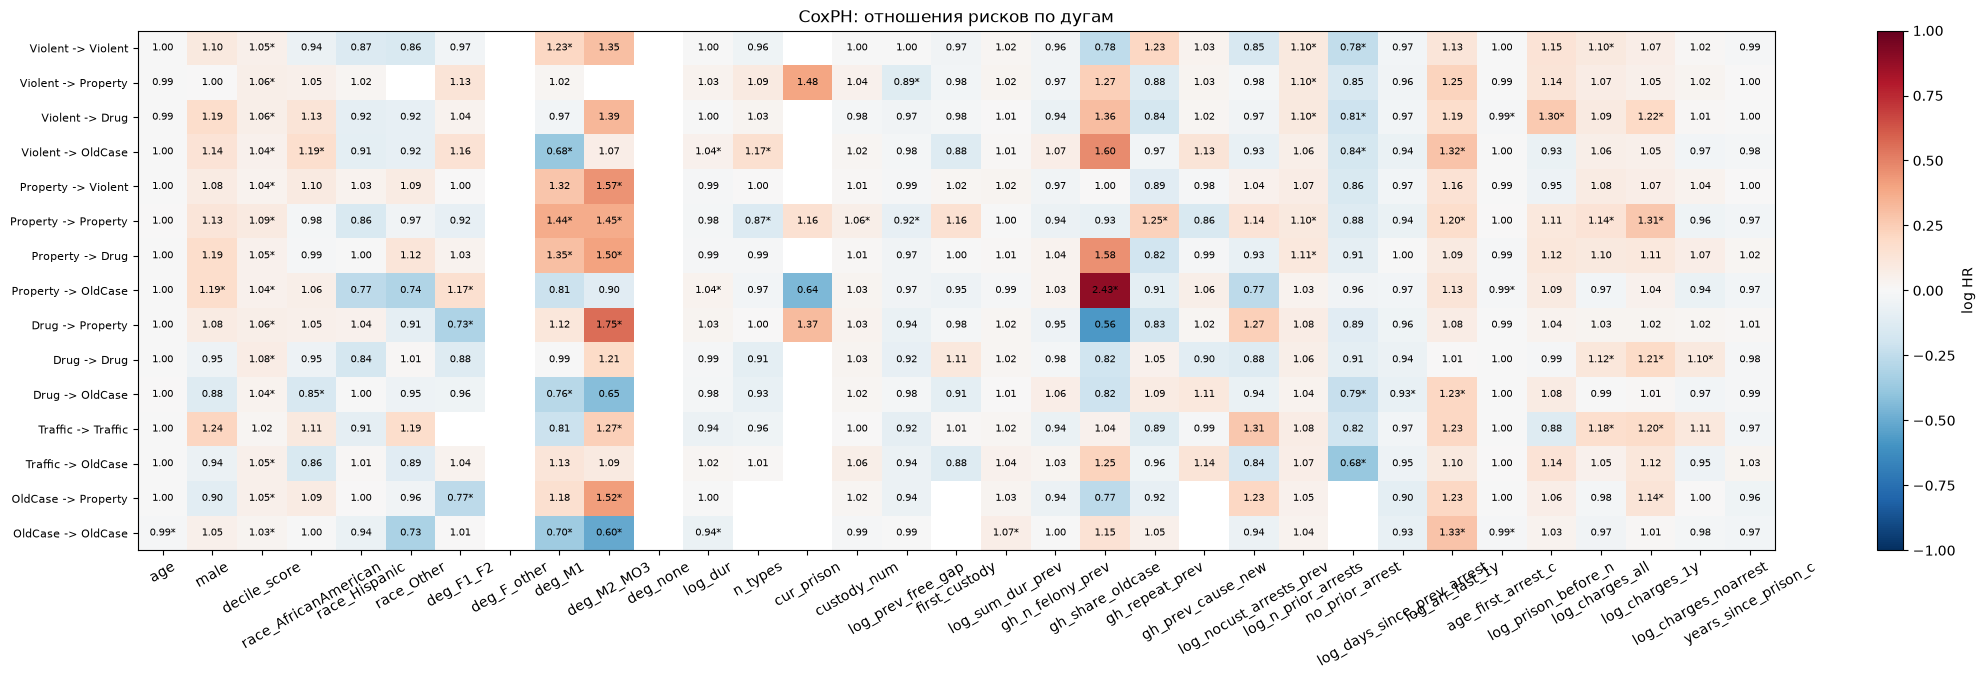

HR на 1 стандартное отклонение признака (1.00 - нет эффекта; пусто - признак убран из модели дуги):


covariate,age,male,decile_score,race_AfricanAmerican,race_Hispanic,race_Other,deg_F1_F2,deg_F_other,deg_M1,deg_M2_MO3,...,log_n_prior_arrests,no_prior_arrest,log_days_since_prev_arrest,log_arr_last_1y,age_first_arrest_c,log_prison_before_n,log_charges_all,log_charges_1y,log_charges_noarrest,years_since_prison_c
Violent -> Violent,0.99,1.04,1.17,0.97,0.97,0.97,0.99,NaN,1.09,1.08,...,1.11,0.90,0.97,1.06,0.96,1.07,1.09,1.05,1.01,0.99
Violent -> Property,0.92,1.00,1.17,1.03,1.01,NaN,1.05,NaN,1.01,NaN,...,1.11,0.93,0.96,1.11,0.93,1.06,1.07,1.04,1.02,1.00
Violent -> Drug,0.93,1.07,1.19,1.06,0.98,0.98,1.01,NaN,0.99,1.09,...,1.12,0.91,0.97,1.08,0.91,1.12,1.08,1.15,1.01,1.00
Violent -> OldCase,0.95,1.05,1.14,1.09,0.98,0.98,1.06,NaN,0.85,1.02,...,1.07,0.93,0.93,1.14,0.99,0.97,1.05,1.04,0.97,0.98
Property -> Violent,0.95,1.03,1.11,1.05,1.01,1.02,1.00,NaN,1.13,1.13,...,1.08,0.94,0.97,1.07,0.93,0.98,1.07,1.05,1.03,1.01
Property -> Property,1.01,1.05,1.29,0.99,0.96,0.99,0.97,NaN,1.17,1.10,...,1.12,0.94,0.93,1.09,1.04,1.05,1.13,1.21,0.96,0.96
Property -> Drug,0.97,1.07,1.15,0.99,1.00,1.03,1.01,NaN,1.14,1.11,...,1.13,0.96,1.00,1.04,0.92,1.05,1.09,1.08,1.07,1.03
Property -> OldCase,0.96,1.07,1.13,1.03,0.93,0.93,1.06,NaN,0.91,0.97,...,1.04,0.98,0.97,1.06,0.91,1.04,0.97,1.03,0.94,0.96
Drug -> Property,0.98,1.03,1.19,1.03,1.01,0.98,0.89,NaN,1.05,1.16,...,1.09,0.95,0.95,1.04,0.95,1.02,1.03,1.02,1.02,1.01
Drug -> Drug,0.96,0.98,1.25,0.98,0.96,1.00,0.95,NaN,1.00,1.05,...,1.07,0.96,0.94,1.00,1.00,1.00,1.11,1.15,1.10,0.98


Падение C-index на тесте при исключении группы (больше - важнее):


,C полной,объект,текущее заключение,RFM,история по графу,до 2013
arc,,,,,,
Violent -> Violent,0.666,0.015,0.008,0.002,0.001,0.023
Violent -> Property,0.739,0.002,-0.002,-0.004,0.002,0.017
Violent -> Drug,0.780,0.036,-0.008,-0.002,-0.016,0.001
Violent -> OldCase,0.736,0.009,0.012,0.000,-0.001,0.005
Property -> Violent,0.734,0.026,0.046,0.005,-0.009,0.042
Property -> Property,0.726,0.008,0.026,-0.003,0.005,0.033
Property -> Drug,0.757,0.019,0.034,0.002,-0.003,0.017
Property -> OldCase,0.649,0.011,0.010,0.001,-0.001,-0.006
Drug -> Property,0.693,0.015,0.036,0.006,-0.031,-0.017


Сводка по группам (по дугам):


,среднее падение C,"дуг, где падение > 0.01"
объект,0.014,10
текущее заключение,0.012,7
RFM,0.001,0
история по графу,-0.003,0
до 2013,0.017,9


,median_HR,"значим, ускоряет (HR>1)","значим, замедляет (HR<1)",не значим,нет в модели
covariate,,,,,
age,0.997,0,1,14,0
male,1.084,1,0,14,0
decile_score,1.053,14,0,1,0
race_AfricanAmerican,1.051,1,1,13,0
race_Hispanic,0.938,0,0,15,0
race_Other,0.938,0,0,14,1
deg_F1_F2,1.004,1,2,11,1
deg_F_other,NaN,0,0,0,15
deg_M1,1.023,3,3,9,0


In [38]:
# ============================== Этап 3.3. Влияние признаков на переходы ==============================
# Сводка по всем дугам: в скольких дугах признак значим (p < 0.05) и в какую сторону, медиана отношения рисков.
coef = pd.DataFrame({f"{a} -> {b}": m.summary["exp(coef)"] for (a, b), m in cox_models.items()}).T.reindex(columns=feat)
pval = pd.DataFrame({f"{a} -> {b}": m.summary["p"] for (a, b), m in cox_models.items()}).T.reindex(columns=feat)
effect = pd.DataFrame({"median_HR": coef.median().round(3),
                       "значим, ускоряет (HR>1)": ((pval < 0.05) & (coef > 1)).sum(),
                       "значим, замедляет (HR<1)": ((pval < 0.05) & (coef < 1)).sum(),
                       "не значим": (pval >= 0.05).sum(),
                       "нет в модели": pval.isna().sum()})
effect.to_csv(STAGES / "feature_effects.csv")

fig, ax = plt.subplots(figsize=(max(8, 0.8 * len(feat)), 0.35 * len(coef) + 1.5))
im = ax.imshow(np.log(coef.values.astype(float)), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(feat))); ax.set_xticklabels(feat, rotation=30)
ax.set_yticks(range(len(coef))); ax.set_yticklabels(coef.index, fontsize=8)
for i in range(coef.shape[0]):
    for j in range(coef.shape[1]):
        if np.isnan(coef.iat[i, j]):                                   # признак убран из модели дуги
            continue
        ax.text(j, i, f"{coef.iat[i, j]:.2f}" + ("*" if pval.iat[i, j] < 0.05 else ""), ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="log HR"); ax.set_title("CoxPH: отношения рисков по дугам")
plt.show()

# ---- эффект на 1 стандартное отклонение признака: HR_sd = exp(beta * sd), sd - по всем эпизодам этапа 3 ----
# Единицы у признаков разные (годы, баллы, логарифмы, 0/1): сравнивать HR напрямую нельзя, HR_sd - можно.
sd = ep_x[feat].std()
hr_sd = pd.DataFrame({f"{a} -> {b}": np.exp(m.summary["coef"] * sd[m.summary.index]) for (a, b), m in cox_models.items()}).T
hr_sd = hr_sd.reindex(columns=feat)
hr_sd.round(2).to_csv(STAGES / "hr_per_sd.csv")
print("HR на 1 стандартное отклонение признака (1.00 - нет эффекта; пусто - признак убран из модели дуги):")
display(hr_sd.round(2))

# ---- важность групп признаков: падение C-index на тесте при исключении группы ----
# Падение = C полной модели - C модели без группы: больше - группа важнее для прогноза, меньше 0 - группа мешает.
GROUPS = {"объект": feat_obj, "текущее заключение": feat_event, "RFM": feat_hist, "история по графу": GRAPH_FEAT}
if USE_PRE2013:
    GROUPS["до 2013"] = feat_pre2013

def fit_cindex(tr, te, cols):
    m = CoxPHFitter(penalizer=0.01).fit(tr[cols + ["T", "Eb"]], duration_col="T", event_col="Eb")
    return concordance_index_censored(te["Eb"].astype(bool), te["T"], m.predict_partial_hazard(te[cols]).values)[0]

rows_imp = []
for (a, b) in cox_models:
    d = arc_data(a, b)
    tr, te = d[~d["is_test"]], d[d["is_test"]]
    use, _ = usable(tr, feat)
    full = fit_cindex(tr, te, use)
    row = {"arc": f"{a} -> {b}", "C полной": round(full, 3)}
    for gname, cols in GROUPS.items():
        rest = [f for f in use if f not in cols]
        if len(rest) == len(use) or not rest:                 # группы нет в модели дуги
            row[gname] = np.nan
            continue
        row[gname] = round(full - fit_cindex(tr, te, rest), 3)
    rows_imp.append(row)
importance = pd.DataFrame(rows_imp).set_index("arc")
importance.to_csv(STAGES / "importance_by_group.csv")
print("Падение C-index на тесте при исключении группы (больше - важнее):")
display(importance)
summary = pd.DataFrame({"среднее падение C": importance.drop(columns="C полной").mean().round(3),
                        "дуг, где падение > 0.01": (importance.drop(columns="C полной") > 0.01).sum()})
summary.to_csv(STAGES / "importance_summary.csv")
print("Сводка по группам (по дугам):")
display(summary)
effect

In [39]:
import sqlite3, pandas as pd
c = sqlite3.connect(DB)
print(pd.read_sql("SELECT race, COUNT(*) AS n FROM people GROUP BY race ORDER BY n DESC", c))
c.close()

               race     n
0  African-American  5813
1         Caucasian  4085
2          Hispanic  1100
3             Other   661
4             Asian    58
5   Native American    40
